# Task 2: Drug-target affinity prediction and recommendation

## 1. Introduction

We investigate whether collaborative filtering can predict held-out drug-protein affinities more accurately than a constant baseline and use those predictions to rank protein targets for a drug.

The detailed objective in SC4020 Project 2 §2.2, page 3 asks us to rank held-out targets for a ligand represented in training. We follow that objective. The heading, "Recommending a Drug to a Given Target", describes the reverse direction.

| Recommender concept | This application |
|---|---|
| User | Drug/ligand |
| Item | Protein target |
| Rating | Measured binding affinity; higher supplied scores indicate stronger affinity |
| Single prediction | Predicted affinity for `(drug_id, protein_id)` |
| Recommendation query | One drug ranked against proteins with held-out measurements |

We compare Global Mean, Protein-Based KNN, Drug-Based KNN and Biased Matrix Factorization (MF) on DAVIS and KIBA. Jiaxin implemented the first three models; WeiW0917 implemented Biased MF. This notebook uses their supplied implementations.

### How to review

Run the cells from top to bottom. The notebook checks the data, loads eight trained models, reviews the completed experiments, and calculates evaluation metrics and six recommendation cases. It has no training switches. The recorded KNN search and 73-fit MF campaign explain the selected settings; training reproduction is handled separately by `run_models.py` and `run_biased_mf.py`, using the commands in the repository README.

We select the model family with the lowest validation MSE before evaluating test predictions, then keep its settings unchanged. The cases are the three smallest canonical drug IDs with at least ten measured test candidates, chosen independently of prediction outcomes.

Generated tables, plots and checkpoint copies go to `task2/results/task2_submission/review/`; the supplied checkpoints are preserved. No earlier notebook or historical result folder is needed. The submission files are listed in `SUBMISSION.md`.

In [1]:
import sys, json, warnings, gc
from pathlib import Path

ROOT = next((p for p in (Path.cwd(), Path.cwd().parent)
             if (p/'shared_data.py').is_file() and (p/'task2/utils').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Use the submission layout documented in SUBMISSION.md')
ROOT = ROOT.resolve()
SELF = next((p for p in (Path.cwd()/'task2.ipynb', ROOT/'task2.ipynb', ROOT/'task2/task2.ipynb') if p.is_file()), None)
assert SELF is not None
RUN = ROOT/'task2/results/task2_submission/review'
MODEL_DIR = ROOT/'task2/saved_models'
RUN.mkdir(parents=True, exist_ok=True)
(RUN/'checkpoints').mkdir(exist_ok=True)
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore', message="The 'float_precision' argument is deprecated")
EVIDENCE = json.loads(SELF.read_text())['metadata']['task2_evidence']

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
get_ipython().run_line_magic('matplotlib', 'inline')
import shared_data
from shared_data import prepare, canonical_strings, load_mappings, load_task2_split, PAIR_KEYS, TEXT_KEYS, CLEANED, SCHEMA
from task2.utils import global_mean, protein_cf, drug_cf, biased_mf, evaluation

DATASETS = ('davis', 'kiba')
MODULES = {'global_mean': global_mean, 'protein_cf': protein_cf, 'drug_cf': drug_cf, 'biased_mf': biased_mf}
LABELS = {'global_mean': 'Global Mean', 'protein_cf': 'Protein KNN', 'drug_cf': 'Drug KNN', 'biased_mf': 'Biased MF'}
MF_CONFIG = dict(n_factors=128, regularization=1., learning_rate=.001, batch_size=2048, seed=42, patience=10, max_epochs=100)
K_REFERENCE = {'protein_cf': {'davis': 10, 'kiba': 5}, 'drug_cf': {'davis': 5, 'kiba': 10}}
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 80)
pd.set_option('display.max_colwidth', 80)

def table(frame, filename):
    frame.to_csv(RUN/filename, index=False)
    display(frame)

def figure(fig, filename):
    fig.tight_layout()
    fig.savefig(RUN/filename, dpi=300, bbox_inches='tight')
    display(fig)
    plt.close(fig)

print('Load saved models → compare validation results → evaluate test data → show recommendations')
print('Tables and figures:', RUN.relative_to(ROOT))

Load saved models → compare validation results → evaluate test data → show recommendations
Tables and figures: task2/results/task2_submission/review


## 2. Data preparation

Each observation contains `compound_iso_smiles`, `target_sequence` and `affinity`. A single call to `shared_data.prepare()` checks cleaning, creates canonical IDs and reconstructs the fixed partitions. Sections 2 to 4 examine these stages.

Scores are parsed as numbers. We exclude nonfinite scores and missing or blank identifiers, strip whitespace from identifiers, and average repeated exact SMILES-sequence pairs. Valid extreme scores and genuine KIBA zeros are retained. Recomputed means are compared with the validated cleaned CSVs using an absolute tolerance of $10^{-12}$. The original decimal values are preserved: compact split assignments retain the original affinity tokens, whose differences from cleaned-file serialization are at most $1.78\times10^{-15}$.

The brief describes raw DAVIS $K_d$ in nM, converted using $pK_d=9-\log_{10}(K_d)$. Our supplied DAVIS CSV already contains pKd, as established during data preparation, with many screening-limit records at 5. We therefore apply no further logarithm. The range checks support this data provenance, although a numeric range alone cannot establish units. KIBA retains its supplied transformed scores. Higher scores indicate stronger affinity in both datasets, but their units differ, so raw error magnitudes should not be compared across datasets.

The brief lists 68/442 DAVIS ligands/targets and 2,111/229 KIBA ligands/targets. The exact strings in our CSVs identify 68/379 and 2,068/229 unique entities. Original benchmark IDs are absent, so we report the observed string identities and pair counts before and after deduplication.

The histograms show the distributions of measured scores, including the DAVIS concentration at pKd 5. Unmeasured KIBA interactions contribute to the sparsity calculation, not to the histogram as zero-valued observations.

DAVIS raw observation examples


,compound_iso_smiles,target_sequence,affinity
0,O=C(NC1CCNCC1)c1[nH]ncc1NC(=O)c1c(Cl)cccc1Cl,MVSYWDTGVLLCALLSCLLLTGSSSGSKLKDPELSLKGTQHIMQAGQTLHLQCRGEAAHKWSLPEMVSKESERLSI...,5.0
1,CSc1cccc(Nc2ncc3cc(-c4c(Cl)cccc4Cl)c(=O)n(C)c3n2)c1,MLRGGRRGQLGWHSWAAGPGSLLAWLILASAGAAPCPDACCPHGSSGLRCTRDGALDSLHHLPGAENLTELYIENQ...,5.0


KIBA raw observation examples


,compound_iso_smiles,target_sequence,affinity
0,O=C1c2c(c3c4ccc(O)cc4n(C4OC(CO)C(O)C(O)C4O)c3c3[nH]c4cc(O)ccc4c23)C(=O)N1NC(...,MSANNSPPSAQKSVLPTAIPAVLPAASPCSSPKTGLSARLSNGSFSAPSLTNSRGSVHTVSFLLQIGLTRESVTIE...,9.79897
1,N#Cc1ccc(NC(=O)Nc2ccnc3cc(C(F)(F)F)ccc23)nc1,MLGAVEGPRWKQAEDIRDIYDFRDVLGTGAFSEVILAEDKRTQKLVAIKCIAKEALEGKEGSMENEIAVLHKIKHP...,11.40000


,dataset,raw_rows,raw_unique_drugs,raw_unique_proteins,cleaned_rows,drugs,proteins,duplicate_excess,invalid_scores,invalid_ids,coverage,sparsity,min_score,max_score,genuine_zero_scores
0,davis,30056,68,379,25772,68,379,4284,0,0,1.000000,0.000000,5.0,10.619789,0
1,kiba,118254,2068,229,117657,2068,229,597,0,0,0.248446,0.751554,0.0,17.200179,1


,dataset,raw_rows,invalid_scores,invalid_ids,duplicate_excess,drugs,proteins,cleaned_rows,score_scale,score_transformation,cleaned_reference,reclean_max_abs_difference,reclean_nonidentical_floats,cleaned_serialization_policy
0,davis,30056,0,0,4284,68,379,25772,supplied pKd,none,task2/data/davis_clean_task2.csv,1.776357e-15,121,retain exact validated cleaned cells after mean-aggregation audit
1,kiba,118254,0,0,597,2068,229,117657,supplied transformed KIBA,none,data/kiba_clean.csv,0.000000e+00,0,retain exact validated cleaned cells after mean-aggregation audit


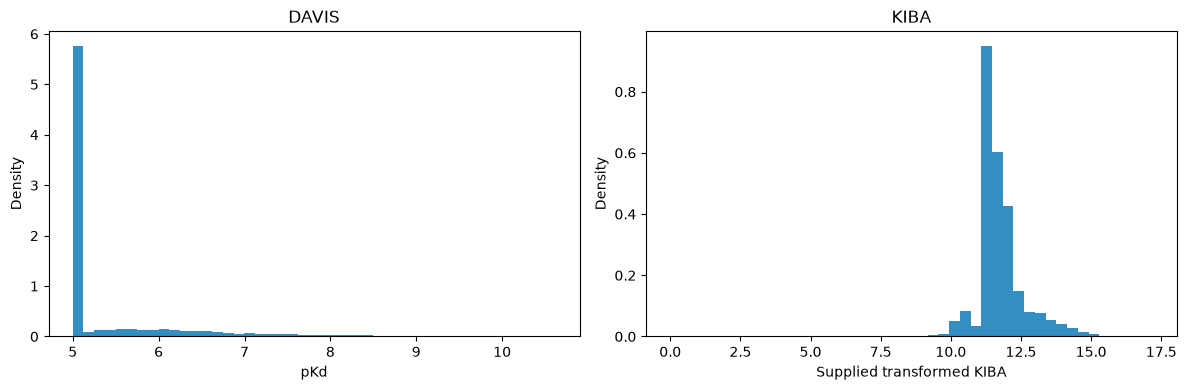

In [2]:
preparation = prepare(root=ROOT)
stats, examples = [], []
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, dataset in zip(axes, DATASETS):
    raw = pd.read_csv(ROOT/'data'/f'{dataset}_all.csv', float_precision='round_trip')
    cleaned = pd.read_csv(ROOT/CLEANED[dataset], float_precision='round_trip')
    audit = next(row for row in preparation['cleaning'] if row['dataset'] == dataset)
    d, p = cleaned[TEXT_KEYS[0]].nunique(), cleaned[TEXT_KEYS[1]].nunique()
    stats.append(dict(dataset=dataset, raw_rows=len(raw), raw_unique_drugs=raw[TEXT_KEYS[0]].nunique(),
        raw_unique_proteins=raw[TEXT_KEYS[1]].nunique(), cleaned_rows=len(cleaned), drugs=d, proteins=p,
        duplicate_excess=audit['duplicate_excess'], invalid_scores=audit['invalid_scores'], invalid_ids=audit['invalid_ids'],
        coverage=len(cleaned)/(d*p), sparsity=1-len(cleaned)/(d*p), min_score=float(cleaned.affinity.min()),
        max_score=float(cleaned.affinity.max()), genuine_zero_scores=int(cleaned.affinity.eq(0).sum())))
    print(dataset.upper(), 'raw observation examples')
    display(raw.head(2))
    ax.hist(cleaned.affinity, bins=45, density=True, color='#0072B2', alpha=.8)
    ax.set(title=dataset.upper(), xlabel='pKd' if dataset == 'davis' else 'Supplied transformed KIBA', ylabel='Density')
    if dataset == 'davis':
        assert 4.9 <= cleaned.affinity.min() <= 5.1 and cleaned.affinity.max() > 10
    assert not cleaned.duplicated(TEXT_KEYS).any() and np.isfinite(cleaned.affinity).all()
    del raw, cleaned
    gc.collect()
statistics = pd.DataFrame(stats)
table(statistics, 'dataset_statistics.csv')
table(pd.DataFrame(preparation['cleaning']), 'cleaning_audit.csv')
figure(fig, 'affinity_distributions.png')

## 3. Canonical ID encoding

Numeric IDs let every model refer to the same drug and protein consistently. For each complete cleaned dataset, sorted unique SMILES receive IDs $0,\ldots,D-1$, and sorted unique protein sequences receive IDs $0,\ldots,P-1$. We assign them before splitting and reuse the mappings across partitions and Task 3. Row order and affinity labels do not affect the mapping.

These dataset-specific IDs are lookup keys. They contain no molecular fingerprints or amino-acid features, and distances between ID numbers have no chemical or biological meaning.

The six input CSVs regenerate four mapping files, two complete indexed datasets, six indexed splits and a preparation report. The checks verify deterministic mappings, reversible identity lookups, original labels and split membership, so extra input copies of these generated files are unnecessary.

In [3]:
maps, mapping_rows = {}, []
for dataset in DATASETS:
    mapping = maps[dataset] = load_mappings(dataset, ROOT)
    cleaned = pd.read_csv(ROOT/CLEANED[dataset], float_precision='round_trip')
    drugs, proteins = canonical_strings(cleaned)
    assert drugs == mapping['drug_strings'] and proteins == mapping['protein_strings']
    shuffled = cleaned[TEXT_KEYS].sample(frac=1, random_state=42).assign(affinity=np.nan)
    assert canonical_strings(shuffled) == (drugs, proteins)
    for kind, strings in (('drug', drugs), ('protein', proteins)):
        inverse = {value: index for index, value in enumerate(strings)}
        assert len(inverse) == len(strings)
        assert all(strings[inverse[value]] == value for value in strings)
        mapping_rows.append(dict(dataset=dataset, entity=kind, entities=len(strings),
            first_id=0, last_id=len(strings)-1, deterministic=True, reversible=True))
    print(dataset.upper(), 'canonical examples')
    display(pd.DataFrame({'drug_id': range(3), 'compound_iso_smiles': drugs[:3]}))
    display(pd.DataFrame({'protein_id': range(3), 'target_sequence': proteins[:3]}))
    del cleaned, shuffled
    gc.collect()
table(pd.DataFrame(mapping_rows), 'canonical_mapping_checks.csv')

DAVIS canonical examples


,drug_id,compound_iso_smiles
0,0,C#Cc1cccc(Nc2ncnc3cc(OCCOC)c(OCCOC)cc23)c1
1,1,C=CC(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1OCCCN1CCOCC1
2,2,CC(C)(C)c1cc(NC(=O)Nc2ccc(-c3cn4c(n3)sc3cc(OCCN5CCOCC5)ccc34)cc2)no1


,protein_id,target_sequence
0,0,AARDSGTGGGSEKMRGSGPRGAGRRRPPSGGGDTPITPASLAGCYSAPRRAPLWTCLLLCAALRTLLASPSNEVNL...
1,1,AASEPDTAGSVRGLPTAHCPVVQDNRTLGDSSAGEIALSTRNVSETRYVSELTLVRVKVAEAGHYTMRAFHEDAEV...
2,2,DDANGKSQTAGFLKGSLGPHAHLWKLDGEIWGSMDSLASLVLCGVSLLLSGTVEGAMDLILINSLPLVSDAETSLT...


KIBA canonical examples


,drug_id,compound_iso_smiles
0,0,Brc1ccc2[nH]c3cnccc3c2c1
1,1,Brc1ccc2[nH]nc(-c3ccccc3)c2c1
2,2,Brc1ccc2c(c1)-c1[nH]ncc1C2


,protein_id,target_sequence
0,0,MAAAAAAGAGPEMVRGQVFDVGPRYTNLSYIGEGAYGMVCSAYDNVNKVRVAIKKISPFEHQTYCQRTLREIKILL...
1,1,MAAAAAQGGGGGEPRRTEGVGPGVPGEVEMVKGQPFDVGPRYTQLQYIGEGAYGMVSSAYDHVRKTRVAIKKISPF...
2,2,MAAAYLDPNLNHTPNSSTKTHLGTGMERSPGAMERVLKVFHYFESNSEPTTWASIIRHGDATDVRGIIQKIVDSHK...


,dataset,entity,entities,first_id,last_id,deterministic,reversible
0,davis,drug,68,0,67,True,True
1,davis,protein,379,0,378,True,True
2,kiba,drug,2068,0,2067,True,True
3,kiba,protein,229,0,228,True,True


## 4. Fixed warm-start data splitting

We reuse the coverage-aware, seed-42 pair assignments: approximately 70% training, 15% validation and 15% test. Compact assignment CSVs preserve the original row order and decimal affinity tokens, including historical serialization differences. We do not draw a new random split.

- Training observations determine means, similarities, biases and factors.
- Validation observations select KNN settings, MF hyperparameters, stopping epochs and the final model family.
- Test observations are checked for structural integrity here. Test predictions and metrics are calculated in Section 10, after validation selection.

Every evaluation drug and protein occurs in training. The task is therefore to predict missing pairs between known entities; it does not assess cold-target generalization. The checks confirm duplicate-free, disjoint partitions, complete pair coverage, consistent canonical IDs and unchanged affinity cells.

In [4]:
parts, split_rows = {}, []
for dataset in DATASETS:
    parts[dataset] = {split: load_task2_split(dataset, split) for split in ('train', 'val', 'test')}
    sets = {split: set(frame[PAIR_KEYS].itertuples(index=False, name=None)) for split, frame in parts[dataset].items()}
    assert sets['train'].isdisjoint(sets['val']) and sets['train'].isdisjoint(sets['test']) and sets['val'].isdisjoint(sets['test'])
    assert sum(map(len, sets.values())) == int(statistics.loc[statistics.dataset.eq(dataset), 'cleaned_rows'].iloc[0])
    for split, frame in parts[dataset].items():
        assert len(sets[split]) == len(frame) and np.isfinite(frame.affinity).all()
        for column in PAIR_KEYS:
            assert pd.api.types.is_integer_dtype(frame[column])
            assert set(frame[column]) <= set(parts[dataset]['train'][column])
        record = next(row for row in preparation['task2_splits'] if row['dataset'] == dataset and row['split'] == split)
        assert record['exact_original_cells'] and record['pairs_disjoint'] and record['warm_start']
        split_rows.append(dict(dataset=dataset, split=split, observations=len(frame), drugs=frame.drug_id.nunique(),
            proteins=frame.protein_id.nunique(), fraction=len(frame)/sum(len(f) for f in parts[dataset].values()),
            pairs_disjoint=True, canonical_trace_verified=True, original_cells_preserved=True))
table(pd.DataFrame(split_rows), 'split_checks.csv')

,dataset,split,observations,drugs,proteins,fraction,pairs_disjoint,canonical_trace_verified,original_cells_preserved
0,davis,train,18040,68,379,0.699984,True,True,True
1,davis,val,3865,68,379,0.149969,True,True,True
2,davis,test,3867,68,379,0.150047,True,True,True
3,kiba,train,82359,2068,229,0.699992,True,True,True
4,kiba,val,17648,1967,228,0.149995,True,True,True
5,kiba,test,17650,1951,225,0.150012,True,True,True


## 5. Collaborative filtering methods

### 5.1 Global Mean (Jiaxin)

Global Mean gives every pair the same prediction: the average training affinity. It provides a simple reference for deciding whether personalized models improve prediction. For observed training pairs $\Omega_{tr}$, $\mu=\frac{1}{N}\sum_{(d,t)\in\Omega_{tr}}y_{dt}$ and $\hat y_{dt}=\mu$.

Its training MSE equals the population variance. CI is 0.5 when actual scores differ because all predictions tie. Its Hit@K depends on deterministic tie-breaking rather than a learned preference for individual targets.

### 5.2 Protein-Based KNN (Jiaxin)

Protein KNN starts from a target's training mean and adjusts it using the drug's scores on proteins with similar training affinity patterns. A neighbor contributes how far that drug's observed affinity lies above or below the neighbor's mean.

Rows of the affinity matrix are drugs and columns are proteins. Pearson correlation between proteins $i,j$ uses only drugs observed for both, with means calculated over their common observations:

$$r_{ij}=\frac{\sum_{d\in C_{ij}}(y_{di}-\bar y_{i,C})(y_{dj}-\bar y_{j,C})}{\sqrt{\sum_{d\in C_{ij}}(y_{di}-\bar y_{i,C})^2\sum_{d\in C_{ij}}(y_{dj}-\bar y_{j,C})^2}},\qquad
w_{ij}=\operatorname{clip}(r_{ij},0,1)\frac{|C_{ij}|}{|C_{ij}|+10}.$$

The overlap term reduces the weight of correlations based on few common drugs. Undefined correlations and self-similarities are zero, and at least two common observations are required. For a query drug, we retain up to K positive-similarity neighbors with observed training scores, breaking similarity ties by canonical ID. Prediction uses full training protein means $\mu_i$:

$$\hat y_{di}=\mu_i+\frac{\sum_{j\in N_K(d,i)}w_{ij}(y_{dj}-\mu_j)}{\sum_{j\in N_K(d,i)}w_{ij}}.$$

Illustrative example, not a dataset result: suppose the target mean is 6 and there is one usable neighbor. If that neighbor's mean is 5 and this drug's observed score for it is 7, the prediction is 8. The adjustment reflects the drug's above-average score for its neighbor.

With no usable neighbor, prediction falls back to the target's training mean; an unknown target uses the global mean. Missing interactions stay NaN, while genuine zero scores remain observations. Small overlaps can make correlations unreliable, and floating-point differences can change which near-tied neighbor enters the top K.

### 5.3 Drug-Based KNN (Jiaxin)

Drug KNN estimates an affinity from other drugs measured against the same protein. It starts with the query drug's mean and adds weighted deviations from neighboring drug means. Transposing the matrix makes proteins the rows and drugs the columns, allowing the same item-CF implementation to compare drugs across common training proteins:

$$\hat y_{dt}=\mu_d+\frac{\sum_{e\in N_K(d,t)}w_{de}(y_{et}-\mu_e)}{\sum_{e\in N_K(d,t)}w_{de}}.$$

A known drug with no suitable neighbor uses its training mean; an unknown drug uses the global mean. The name describes the similarity calculation. We still predict drug-protein affinities and rank proteins for a given drug.

### 5.4 Biased MF (WeiW0917)

Biased MF combines average tendencies with learned interaction patterns. The fixed training mean $\mu$ gives a common starting point. Drug and protein biases adjust for entities whose scores tend to be higher or lower, while the factor dot product models the remaining pair-specific pattern:

$$\hat y_{dt}=\mu+b_d+c_t+p_d^\top q_t,\qquad P\in\mathbb{R}^{D\times F},\quad Q\in\mathbb{R}^{T\times F}.$$

Here D and T are the numbers of drugs and targets, and F is the latent dimension. The factors are learned from training affinities. With $e_{dt}=\hat y_{dt}-y_{dt}$, the loss combines squared prediction error with an L2 penalty on biases and factors; the fixed mean is excluded:

$$L=\frac{\sum_{(d,t)\in\Omega_{tr}}e_{dt}^2+\lambda(\|b\|^2+\|c\|^2+\|P\|_F^2+\|Q\|_F^2)}{2N}.$$

The gradients describe how each parameter changes the training loss. For example, $\partial L/\partial b_d=N^{-1}\sum_t e_{dt}+(\lambda/N)b_d$ and
$\partial L/\partial p_d=N^{-1}\sum_t e_{dt}q_t+(\lambda/N)p_d$; protein terms are analogous.
Each minibatch uses its mean data gradient plus $(\lambda/N)\theta$. Using $\lambda/B$ would make the regularization coefficient depend on batch size. Repeated IDs contribute through summed gradients, and both factor gradients use pre-update parameters.

Adam adjusts parameter steps using moving averages of gradients and squared gradients: $m_s=0.9m_{s-1}+0.1g_s$, $v_s=0.999v_{s-1}+0.001g_s^2$, with bias-corrected moments and
$\theta_s=\theta_{s-1}-\alpha\hat m_s/(\sqrt{\hat v_s}+10^{-8})$. The L2 term is part of the gradient, so this is ordinary Adam with coupled L2, not AdamW. Biases start at zero; factors use seeded Normal(0, 0.01²) draws. We restore the lowest-validation-MSE epoch, including epoch zero, with patience 10. Validation selects the stopping point but supplies no gradients. Unknown IDs are rejected, so this implementation requires warm-start entities.

The five supplied `task2/utils/*.py` modules implement fitting, prediction, serialization and evaluation. The notebook calls those implementations to organize the experiments and present their results.

In [5]:
def predict(kind, model, frame):
    result = getattr(MODULES[kind], 'predict_'+kind)(model, frame[PAIR_KEYS])
    prediction, fallback = result if isinstance(result, tuple) else (result, None)
    assert prediction.shape == (len(frame),) and np.isfinite(prediction).all()
    return prediction, fallback

def measured_metrics(frame, prediction):
    counts = frame.groupby('drug_id').protein_id.transform('size')
    eligible = counts.to_numpy() > 5
    supplementary = evaluation.hit_at_k(frame.loc[eligible], prediction[eligible], 5)
    return dict(mse=evaluation.mean_squared_error(frame.affinity, prediction),
        ci=evaluation.concordance_index(frame.affinity, prediction),
        hit_at_1=evaluation.hit_at_k(frame, prediction, 1)['hit_rate'],
        hit_at_5=evaluation.hit_at_k(frame, prediction, 5)['hit_rate'],
        hit_at_5_candidates_gt_5=supplementary['hit_rate'], eligible_drugs_gt_5=supplementary['eligible_ligands'])

def verify_alignment(dataset, kind, model):
    mapping = maps[dataset]
    assert str(model['canonical_schema']) == SCHEMA
    for entity in ('drug', 'protein'):
        assert str(model[entity+'_mapping_sha256']) == mapping[entity+'_mapping_sha256']
    if kind != 'global_mean':
        np.testing.assert_array_equal(model['drugs'], np.arange(mapping['n_drugs']))
        np.testing.assert_array_equal(model['targets' if kind == 'biased_mf' else 'proteins'], np.arange(mapping['n_proteins']))
    if kind in ('protein_cf', 'drug_cf'):
        train = parts[dataset]['train']
        rows, columns = ('drug_id', 'protein_id') if kind == 'protein_cf' else ('protein_id', 'drug_id')
        assert np.isfinite(model['values']).sum() == len(train)
        np.testing.assert_array_equal(model['values'][train[rows], train[columns]], train.affinity)
        for split in ('val', 'test'):
            frame = parts[dataset][split]
            assert np.isnan(model['values'][frame[rows], frame[columns]]).all()

## 6. Training procedure and saved models

The supplied checkpoints were fitted before this review. Global Mean used the training average; the KNN models learned training means and similarities; MF fitted biases and factors with Adam and validation early stopping. Their fitting functions are in `task2/utils/`. The following code loads these states without retraining them.

MF uses F=128, λ=1, learning rate=.001, batch size 2048, seed 42 and patience 10. The KNN settings are:

| Model | DAVIS K | KIBA K |
|---|---:|---:|
| Protein KNN | 10 | 5 |
| Drug KNN | 5 | 10 |

Both use minimum overlap 2 and shrinkage 10. Section 7 gives the validation evidence for these choices. For separate reproduction, `run_models.py` refits all four families and `run_biased_mf.py` runs the full MF campaign, following the repository README.

The learning curves come from the selected MF checkpoints. The dashed line marks the restored epoch with the lowest validation MSE. Training can continue after that point until stopping, so the final plotted epoch need not be the saved state.

,dataset,model,operation,training_observations,best_epoch,stopping_epoch
0,davis,Global Mean,saved model; metrics recomputed below,18040,NaN,NaN
1,davis,Protein KNN,saved model; metrics recomputed below,18040,NaN,NaN
2,davis,Drug KNN,saved model; metrics recomputed below,18040,NaN,NaN
3,davis,Biased MF,saved model; metrics recomputed below,18040,74.0,84.0
4,kiba,Global Mean,saved model; metrics recomputed below,82359,NaN,NaN
5,kiba,Protein KNN,saved model; metrics recomputed below,82359,NaN,NaN
6,kiba,Drug KNN,saved model; metrics recomputed below,82359,NaN,NaN
7,kiba,Biased MF,saved model; metrics recomputed below,82359,34.0,44.0


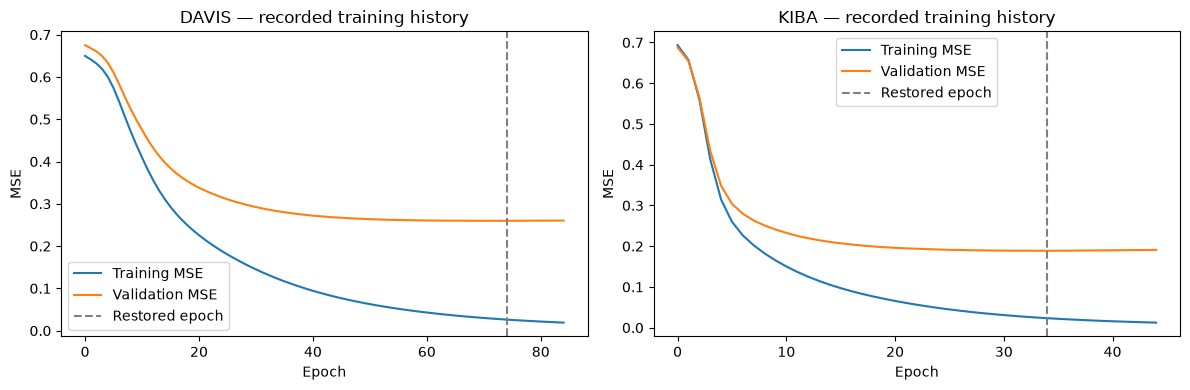

In [6]:
reference_selection = pd.DataFrame(EVIDENCE['tables']['final_selection'])
for key, value in MF_CONFIG.items():
    assert reference_selection[key].eq(value).all(), key
models, origins, activities = {}, {}, []
for dataset in DATASETS:
    models[dataset], origins[dataset] = {}, {}
    train, val = parts[dataset]['train'], parts[dataset]['val']
    for kind, module in MODULES.items():
        suffix = '.json' if kind == 'global_mean' else '.npz'
        path = MODEL_DIR/f'{dataset}_{kind}{suffix}'
        model = getattr(module, 'load_'+kind)(path)
        origin = 'saved model; metrics recomputed below'
        verify_alignment(dataset, kind, model)
        if kind == 'biased_mf':
            for key, value in MF_CONFIG.items():
                assert np.asarray(model[key]).item() == value
        models[dataset][kind], origins[dataset][kind] = model, origin
        activities.append(dict(dataset=dataset, model=LABELS[kind], operation=origin,
            training_observations=len(train),
            best_epoch=int(model['best_epoch']) if kind == 'biased_mf' else None,
            stopping_epoch=int(model['epochs_run']) if kind == 'biased_mf' else None))
table(pd.DataFrame(activities), 'loaded_models.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, dataset in zip(axes, DATASETS):
    model = models[dataset]['biased_mf']
    history = model['history']
    ax.plot(history[:, 0], history[:, 1], label='Training MSE')
    ax.plot(history[:, 0], history[:, 2], label='Validation MSE')
    ax.axvline(int(model['best_epoch']), color='gray', linestyle='--', label='Restored epoch')
    ax.set(title=f'{dataset.upper()} — recorded training history', xlabel='Epoch', ylabel='MSE')
    ax.legend()
figure(fig, 'selected_mf_learning_curves.png')

## 7. Hyperparameter experiments

### 7.1 KNN: completed validation search

The recorded search tested K ∈ {5,10,20,30} and minimum overlap ∈ {2,5,10}, with shrinkage 10. Its 48 dataset/model/configuration results are embedded in this notebook. The plots show these previously measured values; no search is rerun during review.

Training observations determined similarities and means. Validation MSE selected K and overlap, with smaller K and then smaller overlap breaking exact ties. Test scores were excluded. The code checks that the checkpoints use the selected settings, and Section 8 recalculates their validation predictions.

Each plot compares K values for one dataset and KNN method. The lines show how the overlap threshold changes validation error, making the selected combination visible rather than treating K as an arbitrary choice.

Recorded KNN validation search — not rerun by this notebook


,dataset,fallback_fraction,k,min_common,model,validation_mse
0,davis,0.000000,5,2,protein_cf,0.287675
1,davis,0.000000,5,5,protein_cf,0.287675
2,davis,0.000000,5,10,protein_cf,0.287675
3,davis,0.000000,10,2,protein_cf,0.282732
4,davis,0.000000,10,5,protein_cf,0.282732
5,davis,0.000000,10,10,protein_cf,0.282732
6,davis,0.000000,20,2,protein_cf,0.298709
7,davis,0.000000,20,5,protein_cf,0.298709
8,davis,0.000000,20,10,protein_cf,0.298709
9,davis,0.000000,30,2,protein_cf,0.312811


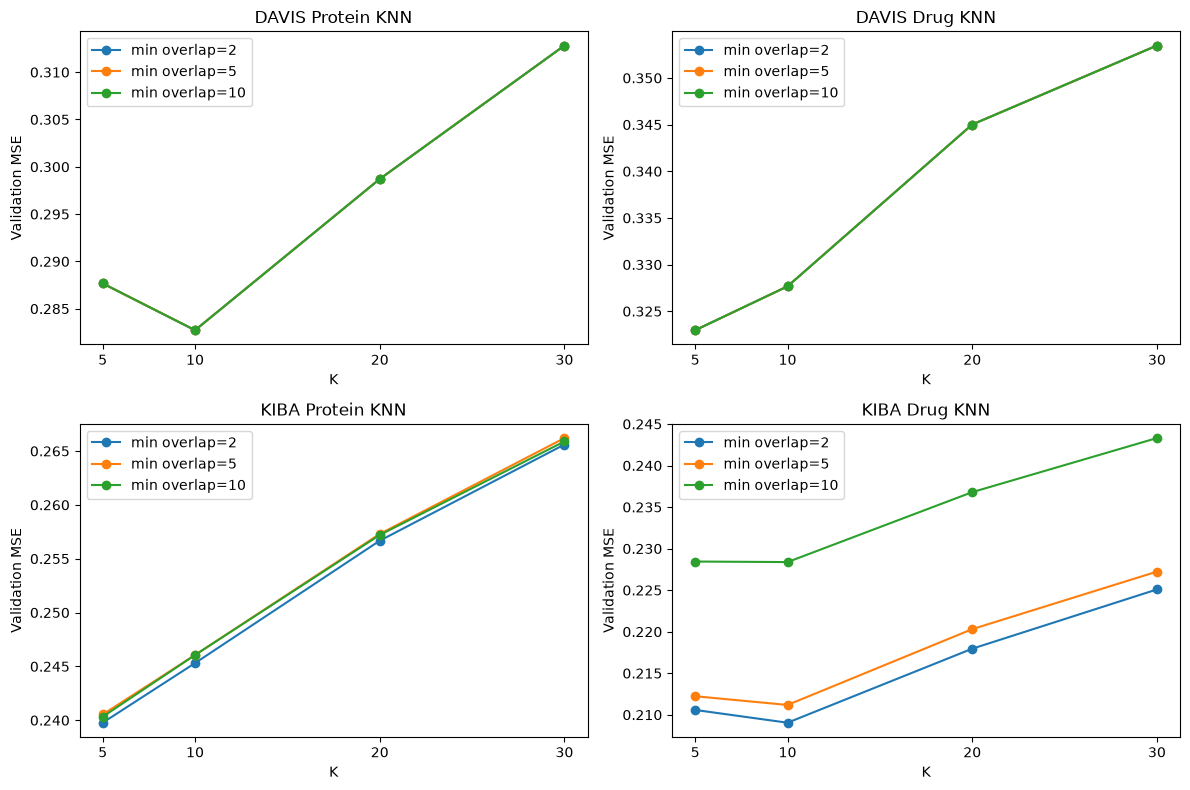

In [7]:
knn_search = pd.DataFrame(EVIDENCE['knn_validation_search'])
assert len(knn_search) == 48
for dataset in DATASETS:
    for kind in ('protein_cf', 'drug_cf'):
        group = knn_search.query('dataset == @dataset and model == @kind')
        chosen = group.sort_values(['validation_mse', 'k', 'min_common'], kind='stable').iloc[0]
        assert int(models[dataset][kind]['k']) == int(chosen.k)
        assert int(models[dataset][kind]['min_common']) == int(chosen.min_common)
print('Recorded KNN validation search — not rerun by this notebook')
table(knn_search, 'knn_validation_search.csv')
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, dataset in enumerate(DATASETS):
    for j, kind in enumerate(('protein_cf', 'drug_cf')):
        group = knn_search.query('dataset == @dataset and model == @kind')
        for overlap, subset in group.groupby('min_common'):
            axes[i,j].plot(subset.k, subset.validation_mse, marker='o', label=f'min overlap={overlap}')
        axes[i,j].set(title=f'{dataset.upper()} {LABELS[kind]}', xlabel='K', ylabel='Validation MSE', xticks=[5,10,20,30])
        axes[i,j].legend()
figure(fig, 'knn_validation_grid.png')

### 7.2 Biased MF: recorded 73-fit campaign

The full-precision tables and raw epoch histories are embedded from the verified canonical-ID campaign. Metadata records the source-table SHA-256 hashes, training-source/data fingerprints and Python/NumPy/pandas versions. The work began from repository commit `77bba05`, and the canonical-ID reproduction was run afterwards. The results therefore belong to that later execution. This notebook reads no earlier notebook, external results CSV or pre-generated PNG.

| Stage | Design and interpretation |
|---|---|
| 1. Capacity | F={8,16,32,64,128}, λ={0,.01}, α=.005, seed 42: 20 conditions |
| 2. Learning curves | Compare raw training and validation histories, including behavior after the best validation epoch |
| 3. Joint interaction | Five F values crossed with λ={0,.01,.1,1,10}: 50 core conditions including the capacity runs |
| 4. Learning rate | The two best F and λ pairs per dataset, with α={.001,.003,.005,.01} |
| 5. Seed robustness | The two best full configurations per dataset, using seeds={42,123,2026}; report mean validation MSE and sample SD |

Batch size 2048, patience 10 and an initial cap of 100 epochs were fixed. During rate/seed refinement, a run that reached the cap with a new validation best in its final ten epochs was replayed from the same seed with a cap of 300. Three DAVIS F64/λ1/α.001 runs met this rule; their first 101 history rows matched the initial runs exactly. The campaign therefore contained 70 base conditions plus three extensions, or 73 physical fits. Final hyperparameters minimized three-seed mean validation MSE, and the handoff checkpoint always used seed 42, even if another seed scored better.

The capacity plots show lower best-validation MSE as F increases over the tested weak-L2 range; they do not establish an inverted-U optimum. The λ=0 and λ=.01 curves are close, so the difference panel shows the small, inconsistent effect of λ=.01 under λ/N scaling. All 20 capacity histories eventually lower training error while raising validation error. This supports restoring the earlier validation-best state; a small error gap alone would not establish adequate fitting.

The interaction heatmaps compare capacity and regularization jointly. The tested combinations favor λ1 at the strongest ranks, and learning-rate refinement improves validation MSE with slower updates. The seed plots show individual scores and mean ± sample SD. Only three seeds were tested, and repeated selection on the same validation set limits statistical claims.

The separate `task2/run_biased_mf.py` command reproduces the full campaign. Review execution regenerates these plots from recorded measurements and evaluates the supplied model checkpoints.

In [8]:
campaign_tables = {name: pd.DataFrame(rows) for name, rows in EVIDENCE['tables'].items()}
campaign_origin = 'Recorded MF experiment'
print('MF experiment provenance:', campaign_origin)
runs = campaign_tables['all_physical_runs']
histories = campaign_tables['all_training_histories']
assert len(runs) == 73 and len(histories) == 3275 and runs.status.eq('ok').all()
assert runs.max_epochs.eq(300).sum() == 3
print('73 recorded fits, 3,275 recorded epochs and three extension runs.')
table(runs[['dataset','n_factors','regularization','learning_rate','seed','max_epochs',
            'train_mse','val_mse','best_epoch','epochs_run']], 'mf_all_73_runs.csv')
table(campaign_tables['stage5_robustness_summary'][['dataset','n_factors','regularization','learning_rate',
                                                'val_mse_mean','val_mse_std','successful_seeds']], 'mf_seed_summary.csv')
summary = campaign_tables['stage5_robustness_summary']
seeds = campaign_tables['stage5_seed_results']
for _, row in summary.iterrows():
    selected_seeds = seeds.loc[seeds.dataset.eq(row.dataset) & seeds.n_factors.eq(row.n_factors)
        & seeds.regularization.eq(row.regularization) & seeds.learning_rate.eq(row.learning_rate)]
    assert set(selected_seeds.seed) == {42,123,2026}
    np.testing.assert_allclose([selected_seeds.val_mse.mean(), selected_seeds.val_mse.std(ddof=1)],
                              [row.val_mse_mean, row.val_mse_std], atol=1e-12, rtol=0)
for dataset in DATASETS:
    winner = summary.loc[summary.dataset.eq(dataset)].sort_values(
        ['val_mse_mean','n_factors','regularization','learning_rate'], kind='stable').iloc[0]
    model = models[dataset]['biased_mf']
    for key in ('n_factors','regularization','learning_rate'):
        assert np.asarray(model[key]).item() == winner[key]
    assert int(model['seed']) == 42

MF experiment provenance: Recorded MF experiment
73 recorded fits, 3,275 recorded epochs and three extension runs.


,dataset,n_factors,regularization,learning_rate,seed,max_epochs,train_mse,val_mse,best_epoch,epochs_run
0,davis,128,1.00,0.001,123,100,0.029494,0.256034,71,81
1,davis,128,1.00,0.001,2026,100,0.021422,0.260665,81,91
2,davis,128,1.00,0.001,42,100,0.026219,0.259842,74,84
3,davis,128,1.00,0.003,42,100,0.028465,0.263022,25,35
4,davis,128,0.00,0.005,42,100,0.023977,0.268324,14,24
5,davis,128,0.01,0.005,42,100,0.024080,0.268317,14,24
6,davis,128,0.10,0.005,42,100,0.019729,0.267810,15,25
7,davis,128,10.00,0.005,42,100,0.185087,0.302430,84,94
8,davis,128,1.00,0.005,42,100,0.031364,0.264120,15,25
9,davis,128,1.00,0.010,42,100,0.023185,0.268846,9,19


,dataset,n_factors,regularization,learning_rate,val_mse_mean,val_mse_std,successful_seeds
0,davis,64,1.0,0.001,0.261293,0.001220,3
1,davis,128,1.0,0.001,0.258847,0.002471,3
2,kiba,128,1.0,0.001,0.189855,0.001323,3
3,kiba,128,1.0,0.003,0.190666,0.001393,3


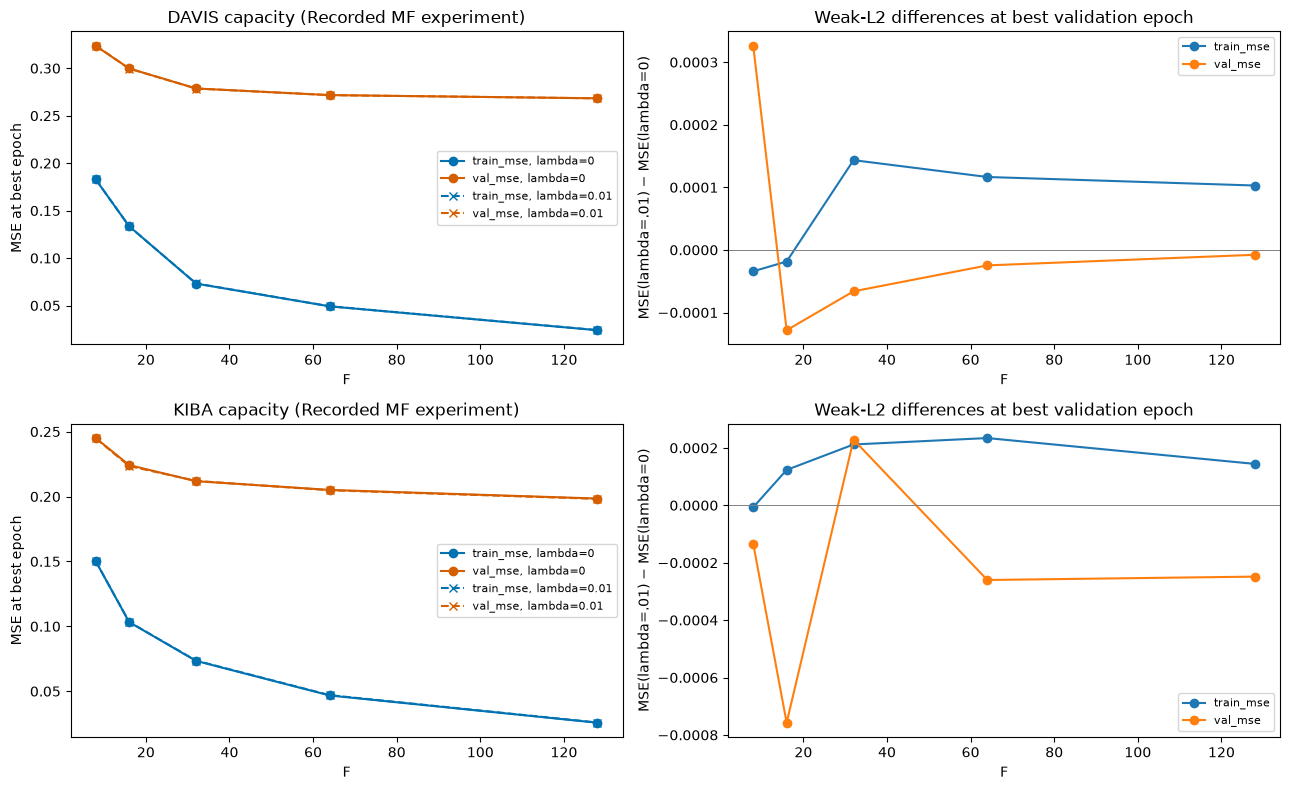

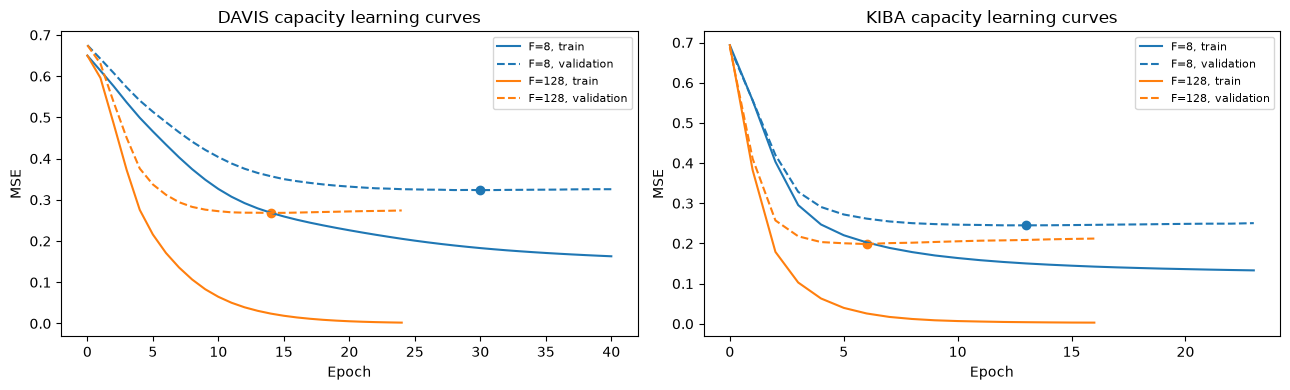

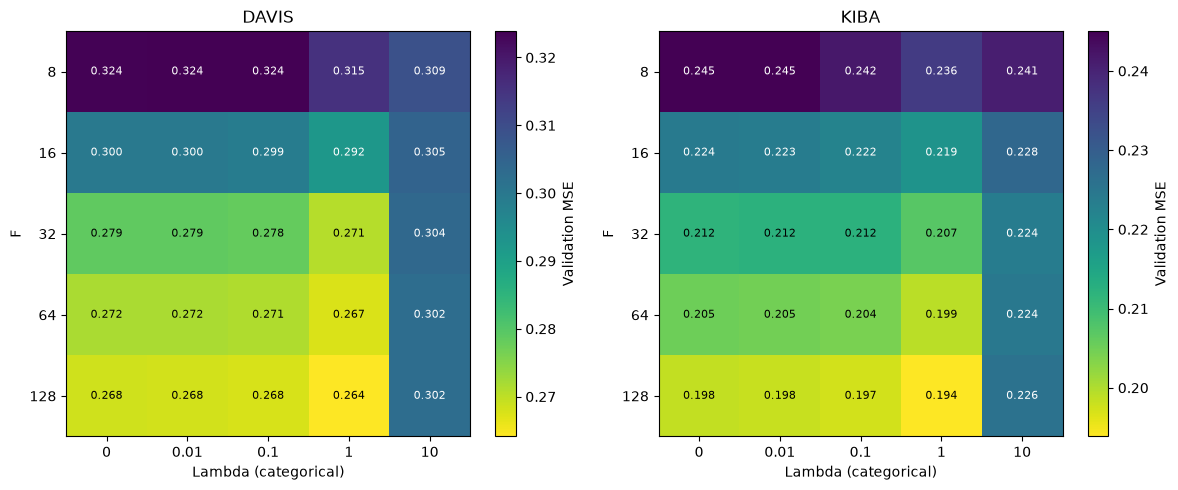

,dataset,n_factors,regularization,train_mse,val_mse,best_epoch,cap_still_improving
0,davis,8,0.00,0.182918,0.323579,30,False
1,davis,8,0.01,0.182884,0.323905,30,False
2,davis,8,0.10,0.183051,0.323780,30,False
3,davis,8,1.00,0.151367,0.315412,56,False
4,davis,8,10.00,0.209456,0.309103,98,True
5,davis,16,0.00,0.133496,0.299793,24,False
6,davis,16,0.01,0.133477,0.299665,24,False
7,davis,16,0.10,0.133907,0.298762,24,False
8,davis,16,1.00,0.102858,0.292319,34,False
9,davis,16,10.00,0.192663,0.304769,98,True


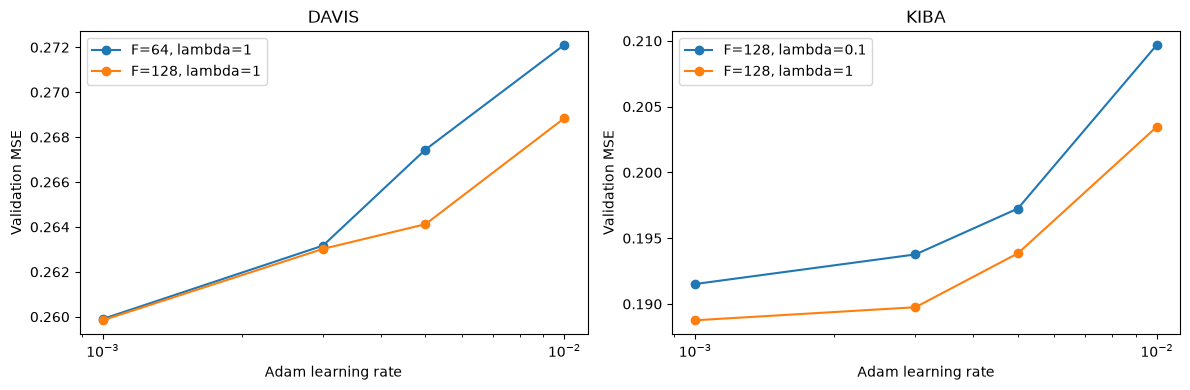

,dataset,n_factors,regularization,learning_rate,val_mse,best_epoch,epochs_run,extension_applied
0,kiba,128,1.0,0.001,0.188761,34,44,False
1,kiba,128,1.0,0.003,0.189752,11,21,False
2,kiba,128,1.0,0.005,0.193851,6,16,False
3,kiba,128,1.0,0.010,0.203476,4,14,False
4,kiba,128,0.1,0.001,0.191518,27,37,False
5,kiba,128,0.1,0.003,0.193768,9,19,False
6,kiba,128,0.1,0.005,0.197257,6,16,False
7,kiba,128,0.1,0.010,0.209704,4,14,False
8,davis,128,1.0,0.001,0.259842,74,84,False
9,davis,128,1.0,0.003,0.263022,25,35,False


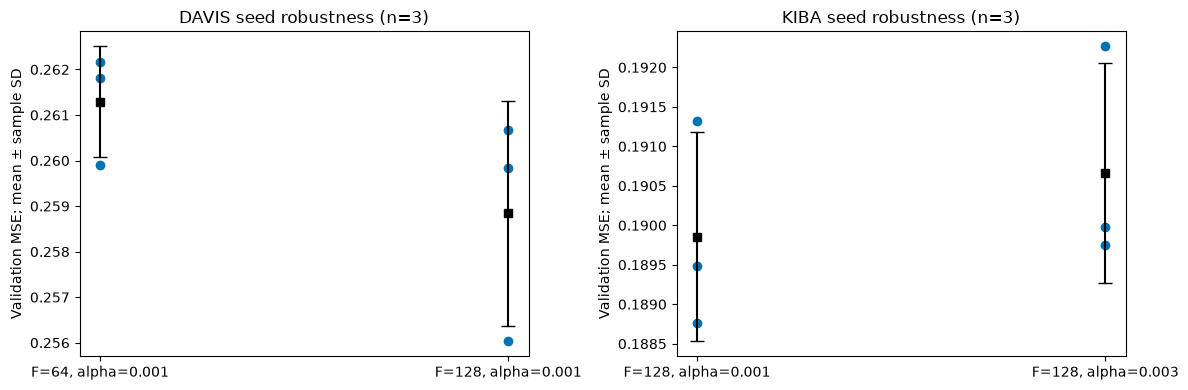

In [9]:
capacity = campaign_tables['stage1_capacity']
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for i, dataset in enumerate(DATASETS):
    sub = capacity.loc[capacity.dataset.eq(dataset)]
    for penalty, style in ((0., '-o'), (.01, '--x')):
        group = sub.loc[sub.regularization.eq(penalty)].sort_values('n_factors')
        for metric, color in (('train_mse','#0072B2'), ('val_mse','#D55E00')):
            axes[i,0].plot(group.n_factors, group[metric], style, color=color, label=f'{metric}, lambda={penalty:g}')
    for metric in ('train_mse', 'val_mse'):
        paired = sub.pivot(index='n_factors', columns='regularization', values=metric)
        axes[i,1].plot(paired.index, paired[.01]-paired[0.], '-o', label=metric)
    axes[i,1].axhline(0, color='gray', linewidth=.7)
    axes[i,0].set(title=f'{dataset.upper()} capacity ({campaign_origin.split(";")[0]})', xlabel='F', ylabel='MSE at best epoch')
    axes[i,1].set(title='Weak-L2 differences at best validation epoch', xlabel='F', ylabel='MSE(lambda=.01) − MSE(lambda=0)')
    axes[i,1].legend(fontsize=8)
    axes[i,0].legend(fontsize=8)
figure(fig, 'mf_capacity_and_weak_l2.png')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, dataset in zip(axes, DATASETS):
    for rank in (8,128):
        row = capacity.loc[capacity.dataset.eq(dataset) & capacity.n_factors.eq(rank) & capacity.regularization.eq(0)].iloc[0]
        trace = histories.loc[histories.run_id.eq(row.run_id)]
        line, = ax.plot(trace.epoch, trace.train_mse, label=f'F={rank}, train')
        ax.plot(trace.epoch, trace.val_mse, '--', color=line.get_color(), label=f'F={rank}, validation')
        ax.scatter([row.best_epoch], [row.val_mse], color=line.get_color())
    ax.set(title=dataset.upper()+' capacity learning curves', xlabel='Epoch', ylabel='MSE')
    ax.legend(fontsize=8)
figure(fig, 'mf_capacity_learning_curves.png')

interaction = campaign_tables['stage3_interaction']
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, dataset in zip(axes, DATASETS):
    matrix = interaction.loc[interaction.dataset.eq(dataset)].pivot(index='n_factors', columns='regularization', values='val_mse')
    image = ax.imshow(matrix, aspect='auto', cmap='viridis_r')
    ax.set(xticks=range(len(matrix.columns)), xticklabels=[f'{x:g}' for x in matrix.columns],
           yticks=range(len(matrix.index)), yticklabels=matrix.index, xlabel='Lambda (categorical)', ylabel='F', title=dataset.upper())
    for i in range(len(matrix)):
        for j in range(len(matrix.columns)):
            ax.text(j, i, f'{matrix.iloc[i,j]:.3f}', ha='center', va='center',
                    color='black' if image.norm(matrix.iloc[i,j]) < .45 else 'white', fontsize=8)
    fig.colorbar(image, ax=ax, label='Validation MSE')
figure(fig, 'mf_regularization_capacity.png')
table(interaction[['dataset','n_factors','regularization','train_mse','val_mse','best_epoch','cap_still_improving']], 'mf_interaction.csv')

rates = campaign_tables['stage4_rates']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, dataset in zip(axes, DATASETS):
    for (rank, penalty), group in rates.loc[rates.dataset.eq(dataset)].groupby(['n_factors','regularization']):
        group = group.sort_values('learning_rate')
        ax.plot(group.learning_rate, group.val_mse, '-o', label=f'F={rank}, lambda={penalty:g}')
    ax.set(xscale='log', xlabel='Adam learning rate', ylabel='Validation MSE', title=dataset.upper())
    ax.legend()
figure(fig, 'mf_learning_rate_refinement.png')
table(rates[['dataset','n_factors','regularization','learning_rate','val_mse','best_epoch','epochs_run','extension_applied']], 'mf_rates.csv')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, dataset in zip(axes, DATASETS):
    sub = summary.loc[summary.dataset.eq(dataset)].reset_index(drop=True)
    for index, row in sub.iterrows():
        values = seeds.loc[seeds.dataset.eq(dataset) & seeds.n_factors.eq(row.n_factors)
            & seeds.regularization.eq(row.regularization) & seeds.learning_rate.eq(row.learning_rate), 'val_mse']
        ax.scatter(np.full(len(values), index), values, color='#0072B2')
        ax.errorbar(index, row.val_mse_mean, yerr=row.val_mse_std, fmt='s', color='black', capsize=5)
    ax.set(xticks=range(len(sub)), xticklabels=[f'F={int(r.n_factors)}, alpha={r.learning_rate:g}' for _,r in sub.iterrows()],
           title=dataset.upper()+' seed robustness (n=3)', ylabel='Validation MSE; mean ± sample SD')
figure(fig, 'mf_seed_robustness.png')

### 7.3 Detailed diagnostics and historical supplement

The model has `(D + T) * (F + 1)` learned bias/factor parameters; increasing F increases this count, and the fixed mean is excluded. DAVIS has only 68 drug rows, so F=128 changes parameterization and optimization but cannot give its interaction matrix rank 128. The capacity study's overfitting flag requires both a training-MSE decrease and a validation-MSE increase greater than 1e-6 after the selected epoch. All 20 capacity histories meet that rule. These are descriptive diagnostics, not significance tests.

The joint grid favors λ=1 for DAVIS F=16–128, while F=8 favors λ=10 within the fixed budget. KIBA favors λ=1 at every F, but its best F changes from 128 to 32 at λ=10. At F=128, increasing λ from 1 to 10 raises both training and validation error. The first plot below compares raw curves at λ=0, 1 and 10, showing the trade-off between fitting and shrinkage. Four strong-penalty core runs were still improving at epoch 100: DAVIS F=8,16,32 and KIBA F=8, all at λ=10. They are budget-limited results, not converged estimates.

Learning-rate refinement uses DAVIS (F=128, λ=1)/(F=64, λ=1) and KIBA (F=128, λ=1)/(F=128, λ=.1). The second plot compares all four rates for each pair using unsmoothed training and validation histories. Rate .001 gives the best validation result in each family but needs more updates; Adam's adaptive scaling does not remove dependence on its base rate. No SGD comparison or wider rate grid was run.

The DAVIS F64/λ1/α.001 seed-42 extension improves validation MSE from 0.260110 at epoch 100 to 0.259899 at epoch 105, then stops at 115. Seed 123 selects epoch 112; seed 2026 retains epoch 97 and stops at 107 without improving its earlier best. The replayed first 101 history rows must match exactly. Computational cost includes both the original run and its replay. The checks below verify all three prefixes and retain the 70-base-plus-three-extension accounting.

Across seeds, DAVIS F128 has lower mean validation MSE than F64 but greater variability and lower mean Hit@K. The best individual DAVIS seed is 123; the handoff still uses the predetermined seed 42. KIBA α=.001 beats .003 on each tested seed, although the mean difference is small relative to the observed variation. Three seeds provide limited stability evidence.

Two earlier F64/λ100/α.005 results are retained below as historical supplementary evidence. They are outside the 73-fit campaign, were not used to select its models and are not rerun here. Their full recorded configurations and source revision are embedded separately from the active campaign tables. The original audit reported exact checkpoint/prediction reloads for 73 successful fits, zero failures and 18 passing software tests, with maximum gradient-check absolute error 1.059e-10. That is a historical audit; this notebook checks the eight currently supplied checkpoints separately.

Verified 73 complete histories, 3,275 epochs and three exact extension prefixes.


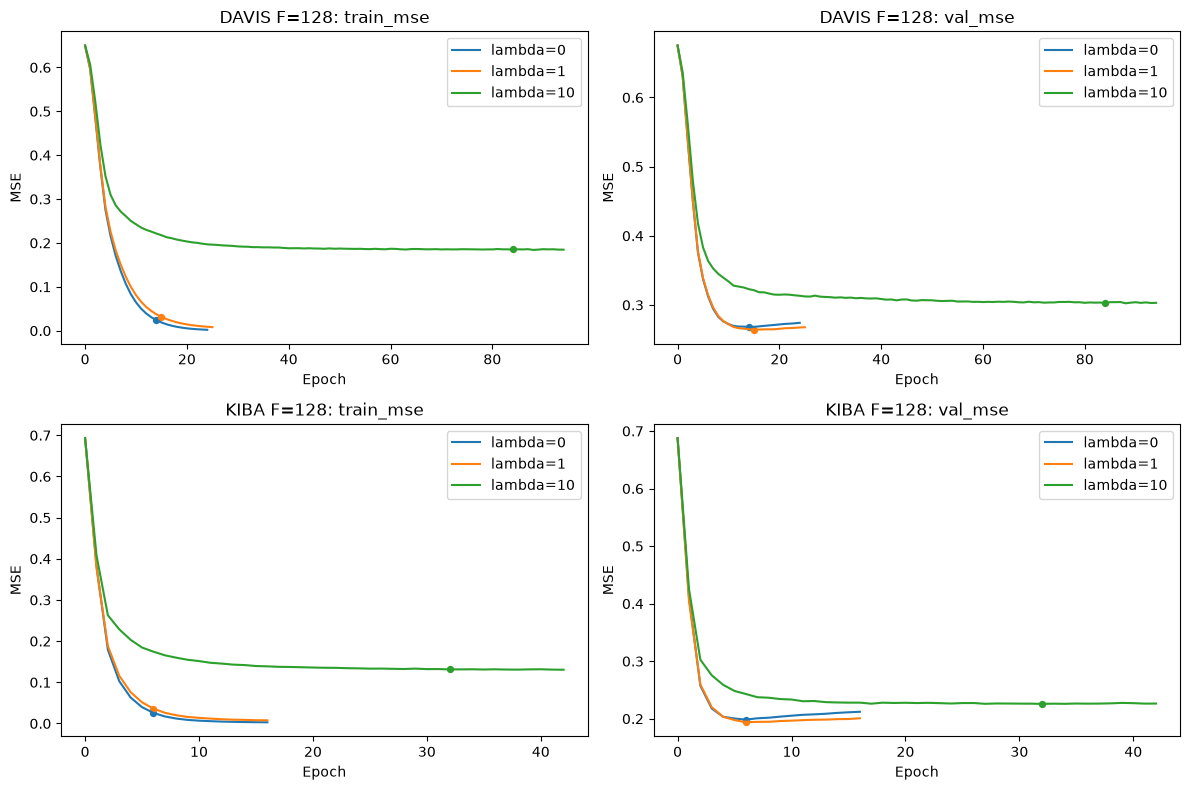

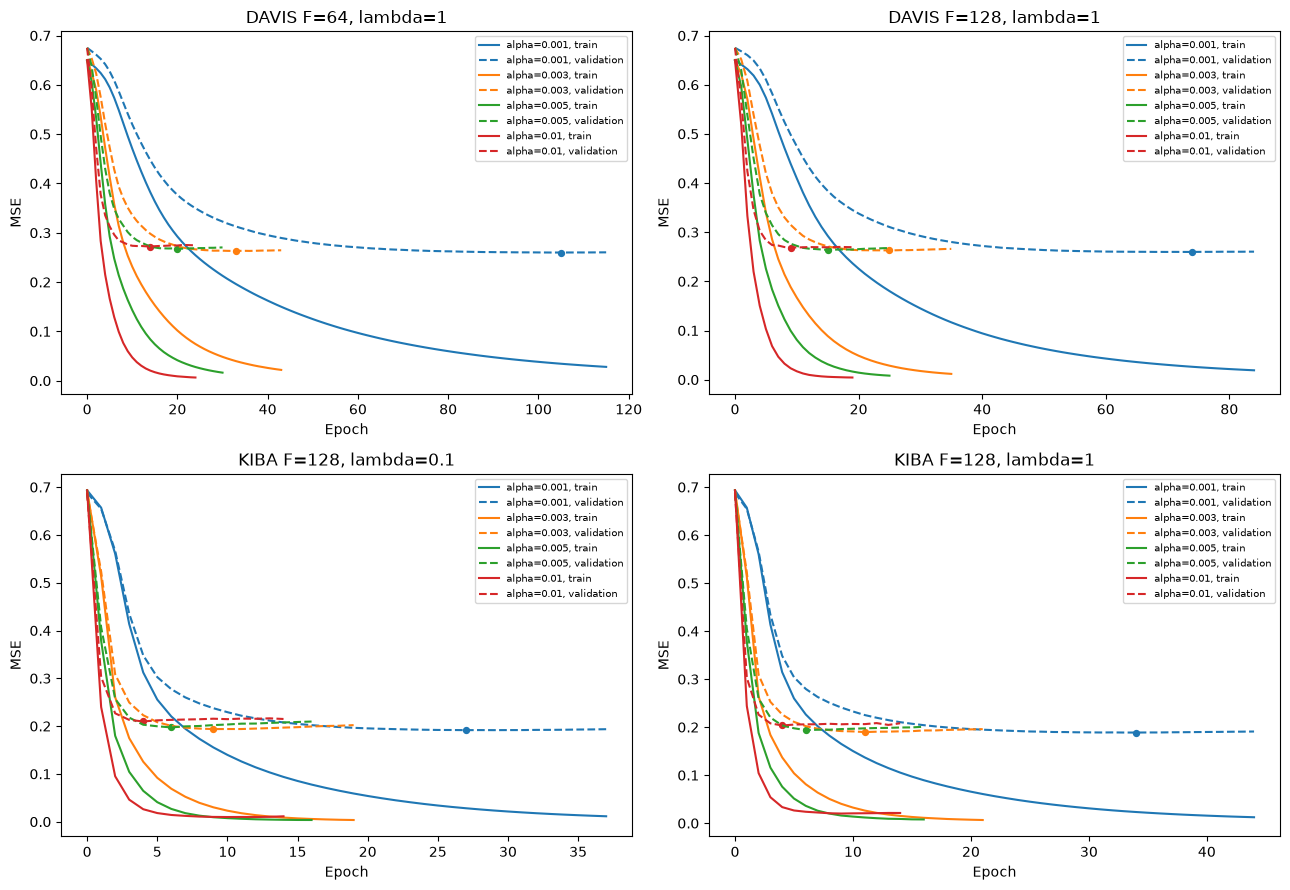

Historical supplementary results only; excluded from the 73-fit campaign and selection.
Source revision: 2b8c1f7894e0e634e20864ea66a561a41b197843 Git blob: 242f8c28c6a231bcf783cd379295867ee30acf4b


,dataset,n_factors,regularization,learning_rate,seed,train_mse,val_mse,best_epoch,epochs_run
0,davis,64,100.0,0.005,42,0.448585,0.487024,72,82
1,kiba,64,100.0,0.005,42,0.503401,0.503147,24,34


,dataset,reference_factors,reference_lambda,reference_alpha,reference_val_mse,selected_val_mse,reduction_absolute,reduction_pct
0,davis,64,0.01,0.005,0.271677,0.259842,0.011835,4.356204
1,davis,64,1.00,0.005,0.267443,0.259842,0.007601,2.842103
2,kiba,64,0.01,0.005,0.204831,0.188761,0.016070,7.845555
3,kiba,64,1.00,0.005,0.199242,0.188761,0.010481,5.260428


In [10]:
assert runs.run_id.is_unique and histories.groupby('run_id').ngroups == 73
for row in runs.itertuples():
    trace = histories.loc[histories.run_id.eq(row.run_id)].sort_values('epoch')
    np.testing.assert_array_equal(trace.epoch, np.arange(int(row.epochs_run) + 1))
    for key in ('dataset', 'n_factors', 'regularization', 'learning_rate', 'seed', 'max_epochs'):
        assert trace[key].eq(getattr(row, key)).all()
for row in runs.loc[runs.max_epochs.eq(300)].itertuples():
    base = runs.loc[runs.max_epochs.eq(100)]
    for key in ('dataset', 'n_factors', 'regularization', 'learning_rate', 'seed'):
        base = base.loc[base[key].eq(getattr(row, key))]
    assert len(base) == 1
    columns = ['epoch', 'train_mse', 'val_mse', 'train_objective']
    prefix = histories.loc[histories.run_id.eq(base.iloc[0].run_id), columns].sort_values('epoch').reset_index(drop=True)
    replay = histories.loc[histories.run_id.eq(row.run_id) & histories.epoch.le(100), columns].sort_values('epoch').reset_index(drop=True)
    assert len(prefix) == 101
    pd.testing.assert_frame_equal(prefix, replay, check_exact=True)
assert len(capacity) == 20 and capacity.overfit_curve_evidence.all()
assert len(interaction) == 50 and interaction.cap_still_improving.sum() == 4
assert len(rates) == 16 and len(seeds) == 12
print('Verified 73 complete histories, 3,275 epochs and three exact extension prefixes.')

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, dataset in enumerate(DATASETS):
    subset = interaction.loc[interaction.dataset.eq(dataset) & interaction.n_factors.eq(128) & interaction.regularization.isin([0, 1, 10])]
    for row in subset.sort_values('regularization').itertuples():
        trace = histories.loc[histories.run_id.eq(row.run_id)].sort_values('epoch')
        for ax, metric in zip(axes[i], ('train_mse', 'val_mse')):
            line, = ax.plot(trace.epoch, trace[metric], label=f'lambda={row.regularization:g}')
            ax.scatter([row.best_epoch], [getattr(row, metric)], color=line.get_color(), s=18)
            ax.set(title=f'{dataset.upper()} F=128: {metric}', xlabel='Epoch', ylabel='MSE')
            ax.legend()
figure(fig, 'mf_regularization_learning_curves.png')

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, ((dataset, factors, penalty), group) in zip(axes.flat, rates.groupby(['dataset', 'n_factors', 'regularization']), strict=True):
    for row in group.sort_values('learning_rate').itertuples():
        trace = histories.loc[histories.run_id.eq(row.run_id)].sort_values('epoch')
        line, = ax.plot(trace.epoch, trace.train_mse, label=f'alpha={row.learning_rate:g}, train')
        ax.plot(trace.epoch, trace.val_mse, '--', color=line.get_color(), label=f'alpha={row.learning_rate:g}, validation')
        ax.scatter([row.best_epoch], [row.val_mse], color=line.get_color(), s=18)
    ax.set(title=f'{dataset.upper()} F={factors}, lambda={penalty:g}', xlabel='Epoch', ylabel='MSE')
    ax.legend(fontsize=7)
figure(fig, 'mf_learning_rate_learning_curves.png')

historical = EVIDENCE['historical_mf_supplement']
supplement = pd.DataFrame(historical['lambda100_results'])
assert len(supplement) == 2 and supplement.regularization.eq(100).all()
assert not runs.regularization.eq(100).any()
print('Historical supplementary results only; excluded from the 73-fit campaign and selection.')
print('Source revision:', historical['source_commit'], 'Git blob:', historical['source_notebook_git_blob'])
table(supplement[['dataset', 'n_factors', 'regularization', 'learning_rate', 'seed', 'train_mse', 'val_mse', 'best_epoch', 'epochs_run']], 'mf_historical_lambda100_supplement.csv')
references = []
for dataset in DATASETS:
    selected_mse = campaign_tables['final_selection'].loc[lambda frame: frame.dataset.eq(dataset), 'val_mse'].iloc[0]
    for row in interaction.loc[interaction.dataset.eq(dataset) & interaction.n_factors.eq(64) & interaction.regularization.isin([.01, 1])].itertuples():
        references.append(dict(dataset=dataset, reference_factors=64, reference_lambda=row.regularization, reference_alpha=row.learning_rate, reference_val_mse=row.val_mse, selected_val_mse=selected_mse, reduction_absolute=row.val_mse-selected_mse, reduction_pct=100*(row.val_mse-selected_mse)/row.val_mse))
table(pd.DataFrame(references), 'mf_reference_comparison.csv')

## 8. Validation and model comparison

MSE measures the average size of prediction errors on the supplied score scale. For $n$ observations, $\mathrm{MSE}=n^{-1}\sum_i(\hat y_i-y_i)^2$; lower values are better.

CI measures ordering agreement. Global CI considers all unordered observation pairs with unequal actual scores, gives 1 for correct predicted ordering and 0.5 for a prediction tie, and excludes actual-score ties. It is undefined when no actual scores differ. Because pairs can come from different drugs, global CI is not an average of per-drug CI values.

Hit@K evaluates the recommendation list for each drug. A hit occurs when any protein tied for the highest actual affinity among its measured held-out candidates appears in the predicted top K. We average this binary result equally across eligible drugs. Prediction ties use ascending integer protein ID. If fewer than K candidates exist, all are included; singletons always hit. Small candidate sets therefore inflate KIBA Hit@5, so we also report Hit@5 for drugs with more than five candidates.

All current metrics are calculated from checkpoint predictions using the shared evaluation functions. We select the family with the lowest validation MSE, breaking exact ties alphabetically by family name. MF's hyperparameters were chosen using three-seed mean validation MSE, while this family comparison uses the fixed handoff seed 42. The comparison plots show training versus validation MSE and the separate ranking metrics, allowing their trade-offs to be assessed.

,dataset,model,train_mse,val_mse,val_ci,val_hit_at_1,val_hit_at_5,hit_at_5_candidates_gt_5,fallback_fraction,origin
0,davis,global_mean,0.649827,0.675120,0.500000,0.102941,0.132353,0.132353,0.000000,saved model; metrics recomputed below
1,davis,protein_cf,0.143402,0.282732,0.866063,0.323529,0.647059,0.647059,0.000000,saved model; metrics recomputed below
2,davis,drug_cf,0.288737,0.322968,0.856107,0.308824,0.676471,0.676471,0.000000,saved model; metrics recomputed below
3,davis,biased_mf,0.026219,0.259842,0.873175,0.338235,0.720588,0.720588,0.000000,saved model; metrics recomputed below
4,kiba,global_mean,0.693327,0.687805,0.500000,0.375699,0.717844,0.449405,0.000000,saved model; metrics recomputed below
5,kiba,protein_cf,0.222928,0.239772,0.826530,0.620234,0.921708,0.847222,0.000057,saved model; metrics recomputed below
6,kiba,drug_cf,0.117055,0.209043,0.848868,0.665989,0.934926,0.873016,0.025442,saved model; metrics recomputed below
7,kiba,biased_mf,0.023247,0.188761,0.848053,0.690391,0.952211,0.906746,0.000000,saved model; metrics recomputed below


,dataset,split,drugs,singleton_drugs,drugs_at_most_5,fraction_at_most_5,median_candidates,max_candidates
0,davis,val,68,0,0,0.000000,57.5,79
1,kiba,val,1967,248,959,0.487544,6.0,32


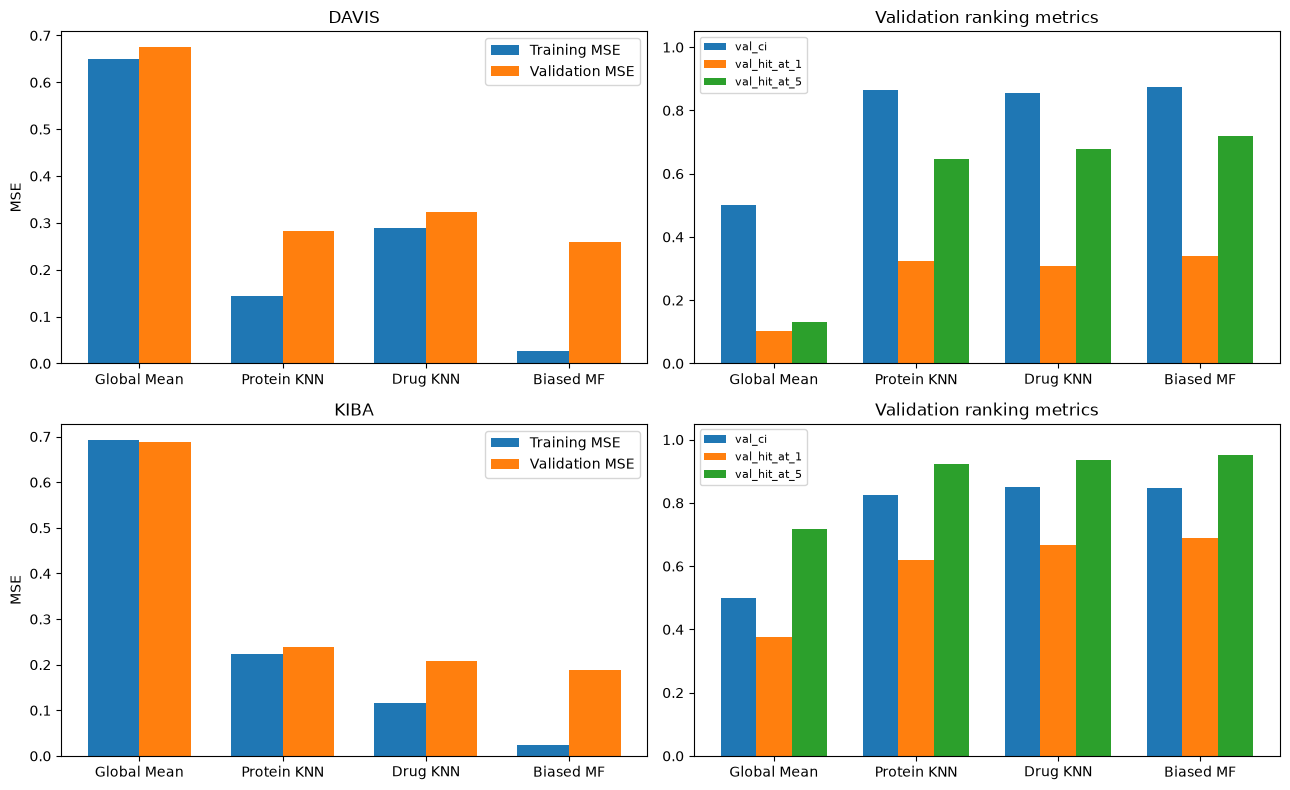

,dataset,model,val_mse
3,davis,biased_mf,0.259842
7,kiba,biased_mf,0.188761


Validation-selected model families: {'davis': 'biased_mf', 'kiba': 'biased_mf'}


In [11]:
predictions, metric_rows, candidate_rows = {}, [], []
for dataset in DATASETS:
    predictions[dataset] = {}
    counts = parts[dataset]['val'].groupby('drug_id').protein_id.nunique()
    candidate_rows.append(dict(dataset=dataset, split='val', drugs=len(counts), singleton_drugs=int(counts.eq(1).sum()),
        drugs_at_most_5=int(counts.le(5).sum()), fraction_at_most_5=float(counts.le(5).mean()),
        median_candidates=float(counts.median()), max_candidates=int(counts.max())))
    for kind in MODULES:
        predictions[dataset][kind] = {}
        for split in ('train','val'):
            predicted, flags = predict(kind, models[dataset][kind], parts[dataset][split])
            predictions[dataset][kind][split] = predicted
            metric_rows.append(dict(dataset=dataset, model=kind, split=split,
                **measured_metrics(parts[dataset][split], predicted),
                fallback_fraction=float(flags.mean()) if flags is not None else 0., origin=origins[dataset][kind]))
metrics = pd.DataFrame(metric_rows)
training_mse = metrics.loc[metrics.split.eq('train'), ['dataset','model','mse']].rename(columns={'mse':'train_mse'})
validation = metrics.loc[metrics.split.eq('val')].merge(training_mse, on=['dataset','model'])
validation = validation.rename(columns={'mse':'val_mse','ci':'val_ci','hit_at_1':'val_hit_at_1','hit_at_5':'val_hit_at_5'})
table(validation[['dataset','model','train_mse','val_mse','val_ci','val_hit_at_1','val_hit_at_5',
                  'hit_at_5_candidates_gt_5','fallback_fraction','origin']], 'validation_comparison.csv')
table(pd.DataFrame(candidate_rows), 'validation_candidate_counts.csv')
selection = validation.sort_values(['dataset','val_mse','model'], kind='stable').groupby('dataset', sort=False).head(1)
winners = dict(zip(selection.dataset, selection.model))
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for i, dataset in enumerate(DATASETS):
    sub = validation.loc[validation.dataset.eq(dataset)]
    x = np.arange(len(sub))
    axes[i,0].bar(x-.18, sub.train_mse, .36, label='Training MSE')
    axes[i,0].bar(x+.18, sub.val_mse, .36, label='Validation MSE')
    axes[i,0].set(xticks=x, xticklabels=[LABELS[k] for k in sub.model], ylabel='MSE', title=dataset.upper())
    axes[i,0].legend()
    for offset, field in zip((-.25,0,.25), ('val_ci','val_hit_at_1','val_hit_at_5')):
        axes[i,1].bar(x+offset, sub[field], .25, label=field)
    axes[i,1].set(xticks=x, xticklabels=[LABELS[k] for k in sub.model], ylim=(0,1.05), title='Validation ranking metrics')
    axes[i,1].legend(fontsize=8)
figure(fig, 'validation_model_comparison.png')
table(selection[['dataset','model','val_mse']], 'selected_models.csv')
print('Validation-selected model families:', winners)

## 9. Model checkpoints and reload verification

Saving a model should preserve its predictions. We copy the eight loaded states to the review output's `checkpoints/` folder using the existing six NPZ and two JSON formats. NPZ files are loaded with `allow_pickle=False`. We then check canonical-ID alignment and exact equality of training/validation predictions before and after reload. These checkpoints support inference but do not contain resumable Adam state.

The supplied files in `task2/saved_models/` are preserved. Model settings and the validation-selected winners remain fixed for test evaluation and the case studies.

In [12]:
checkpoint_paths, verification_rows = {}, []
for dataset in DATASETS:
    checkpoint_paths[dataset] = {}
    for kind, module in MODULES.items():
        suffix = '.json' if kind == 'global_mean' else '.npz'
        path = RUN/'checkpoints'/f'{dataset}_{kind}{suffix}'
        model = models[dataset][kind]
        getattr(module, 'save_'+kind)(model, path)
        loaded = getattr(module, 'load_'+kind)(path)
        verify_alignment(dataset, kind, loaded)
        for split in ('train','val'):
            restored, flags = predict(kind, loaded, parts[dataset][split])
            np.testing.assert_array_equal(restored, predictions[dataset][kind][split])
        checkpoint_paths[dataset][kind] = path
        verification_rows.append(dict(dataset=dataset, model=kind, canonical_alignment=True,
            exact_train_predictions=True, exact_validation_predictions=True,
            checkpoint=str(path.relative_to(ROOT))))
checkpoint_verification = pd.DataFrame(verification_rows)
table(checkpoint_verification, 'checkpoint_verification.csv')

,dataset,model,canonical_alignment,exact_train_predictions,exact_validation_predictions,checkpoint
0,davis,global_mean,True,True,True,task2/results/task2_submission/review/checkpoints/davis_global_mean.json
1,davis,protein_cf,True,True,True,task2/results/task2_submission/review/checkpoints/davis_protein_cf.npz
2,davis,drug_cf,True,True,True,task2/results/task2_submission/review/checkpoints/davis_drug_cf.npz
3,davis,biased_mf,True,True,True,task2/results/task2_submission/review/checkpoints/davis_biased_mf.npz
4,kiba,global_mean,True,True,True,task2/results/task2_submission/review/checkpoints/kiba_global_mean.json
5,kiba,protein_cf,True,True,True,task2/results/task2_submission/review/checkpoints/kiba_protein_cf.npz
6,kiba,drug_cf,True,True,True,task2/results/task2_submission/review/checkpoints/kiba_drug_cf.npz
7,kiba,biased_mf,True,True,True,task2/results/task2_submission/review/checkpoints/kiba_biased_mf.npz


## 10. Final test evaluation

We evaluate all four models on test data after validation selection. A better test score from another model does not replace the chosen winner or change the hyperparameters, checkpoints or case-selection rule.

Earlier Global Mean, Protein CF and Drug CF notebooks at commit `77bba05` already included test evaluations. The test set is therefore not a never-viewed blind holdout. Their notebooks and test numbers are not read here: the following results are recomputed from predictions at the fixed settings. The MF campaign used training and validation only, and these test results are not used to revise the models.

The final MSE plots separate training, validation and test errors for each method. They show how the fitted models perform beyond their training observations, while preserving the validation-based choice.

,dataset,model,split,mse,ci,hit_at_1,hit_at_5,hit_at_5_candidates_gt_5,eligible_drugs_gt_5,fallback_fraction,selected_by_validation,origin
0,davis,global_mean,test,0.679958,0.500000,0.117647,0.176471,0.176471,68,0.000000,False,saved model; metrics recomputed below
1,davis,protein_cf,test,0.289277,0.866785,0.382353,0.823529,0.823529,68,0.000000,False,saved model; metrics recomputed below
2,davis,drug_cf,test,0.312311,0.855041,0.426471,0.735294,0.735294,68,0.000000,False,saved model; metrics recomputed below
3,davis,biased_mf,test,0.252043,0.869981,0.441176,0.794118,0.794118,68,0.000000,True,saved model; metrics recomputed below
4,kiba,global_mean,test,0.717701,0.500000,0.375192,0.708355,0.435516,1008,0.000000,False,saved model; metrics recomputed below
5,kiba,protein_cf,test,0.254573,0.824670,0.590466,0.894413,0.795635,1008,0.000000,False,saved model; metrics recomputed below
6,kiba,drug_cf,test,0.218728,0.847284,0.654024,0.927217,0.859127,1008,0.022436,False,saved model; metrics recomputed below
7,kiba,biased_mf,test,0.199185,0.847978,0.658124,0.935930,0.875992,1008,0.000000,True,saved model; metrics recomputed below


,dataset,model,split,mse,ci,hit_at_1,hit_at_5,hit_at_5_candidates_gt_5,fallback_fraction
0,davis,global_mean,train,0.649827,0.500000,0.000000,0.029412,0.029412,0.000000
1,davis,global_mean,val,0.675120,0.500000,0.102941,0.132353,0.132353,0.000000
2,davis,protein_cf,train,0.143402,0.911076,0.264706,0.661765,0.661765,0.000000
3,davis,protein_cf,val,0.282732,0.866063,0.323529,0.647059,0.647059,0.000000
4,davis,drug_cf,train,0.288737,0.865100,0.205882,0.514706,0.514706,0.000000
5,davis,drug_cf,val,0.322968,0.856107,0.308824,0.676471,0.676471,0.000000
6,davis,biased_mf,train,0.026219,0.975965,0.691176,1.000000,1.000000,0.000000
7,davis,biased_mf,val,0.259842,0.873175,0.338235,0.720588,0.720588,0.000000
8,kiba,global_mean,train,0.693327,0.500000,0.162476,0.343327,0.335616,0.000000
9,kiba,global_mean,val,0.687805,0.500000,0.375699,0.717844,0.449405,0.000000


,dataset,split,drugs,singleton_drugs,drugs_at_most_5,fraction_at_most_5,median_candidates,max_candidates
0,davis,val,68,0,0,0.000000,57.5,79
1,kiba,val,1967,248,959,0.487544,6.0,32
2,davis,test,68,0,0,0.000000,57.0,72
3,kiba,test,1951,244,943,0.483342,6.0,33


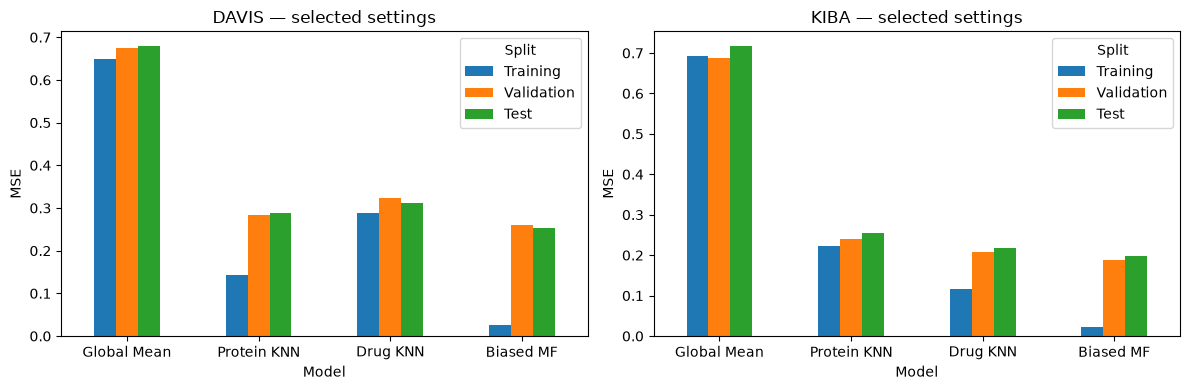

In [13]:
assert set(winners) == set(DATASETS)
test_rows = []
for dataset in DATASETS:
    test = parts[dataset]['test']
    counts = test.groupby('drug_id').protein_id.nunique()
    candidate_rows.append(dict(dataset=dataset, split='test', drugs=len(counts), singleton_drugs=int(counts.eq(1).sum()),
        drugs_at_most_5=int(counts.le(5).sum()), fraction_at_most_5=float(counts.le(5).mean()),
        median_candidates=float(counts.median()), max_candidates=int(counts.max())))
    for kind, module in MODULES.items():
        loaded = getattr(module, 'load_'+kind)(checkpoint_paths[dataset][kind])
        predicted, flags = predict(kind, loaded, test)
        predictions[dataset][kind]['test'] = predicted
        test_rows.append(dict(dataset=dataset, model=kind, split='test', **measured_metrics(test, predicted),
            fallback_fraction=float(flags.mean()) if flags is not None else 0.,
            selected_by_validation=(winners[dataset] == kind), origin=origins[dataset][kind]))
test_metrics = pd.DataFrame(test_rows)
table(test_metrics, 'test_metrics.csv')
all_metrics = pd.concat([metrics, test_metrics], ignore_index=True)
table(all_metrics[['dataset','model','split','mse','ci','hit_at_1','hit_at_5','hit_at_5_candidates_gt_5',
                   'fallback_fraction']], 'train_validation_test_metrics.csv')
table(pd.DataFrame(candidate_rows), 'candidate_counts.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, dataset in zip(axes, DATASETS):
    sub = all_metrics.loc[all_metrics.dataset.eq(dataset)].pivot(index='model', columns='split', values='mse')
    sub = sub.loc[list(MODULES), ['train','val','test']]
    sub.rename(index=LABELS, columns={'train': 'Training', 'val': 'Validation', 'test': 'Test'}).plot.bar(ax=ax, rot=0)
    ax.legend(title='Split')
    ax.set(title=dataset.upper()+' — selected settings', ylabel='MSE', xlabel='Model')
figure(fig, 'final_mse_comparison.png')

## 11. Three fixed test-ligand case studies per dataset

We use the rule declared before evaluation: the three smallest canonical drug IDs with at least ten measured test proteins. This makes the top-five list cover at most half the candidates and selects cases using IDs and coverage, not affinity labels or prediction outcomes. The CSVs lack the benchmark compound IDs suggested in the brief, so each case gives its canonical ID and exact original SMILES.

These are reproducible examples of sufficiently measured test ligands. They exclude low-coverage drugs and are not a random or representative sample. Canonical IDs follow sorted identifiers, which does not guarantee chemical diversity, and ten test candidates do not guarantee useful training overlaps. We use the full test tables to assess overall performance and these cases to examine individual outcomes.

For each case, we load the validation-selected checkpoint from disk and predict only measured held-out pairs; none occurs in training. We rank by decreasing prediction, breaking ties by increasing protein ID. Every target tied for the highest actual affinity is marked "Correct" and all others "Wrong", as requested. These labels refer to the best measured candidate, not to a biochemical binding threshold.

The display includes the top five and every actual-best target ranked outside that list. Full candidate IDs and rankings are also saved. MSE and CI use all measured candidates. CI is undefined if all actual affinities tie; when several targets share the maximum, all their predicted ranks are reported and the smallest determines Hit@K. The best measured candidate may not be the best among unmeasured proteins.

In [14]:
MIN_CASE_CANDIDATES = 10
case_rows, case_rankings = [], {}
for dataset in DATASETS:
    test = parts[dataset]['test']
    counts = test.groupby('drug_id').protein_id.nunique()
    chosen_ids = sorted(counts.loc[counts.ge(MIN_CASE_CANDIDATES)].index.astype(int))[:3]
    assert len(chosen_ids) == 3
    kind = winners[dataset]
    for drug_id in chosen_ids:
        candidates = test.loc[test.drug_id.eq(drug_id)].reset_index(drop=True)
        assert len(candidates) >= MIN_CASE_CANDIDATES
        loaded = getattr(MODULES[kind], 'load_'+kind)(checkpoint_paths[dataset][kind])
        predicted, _ = predict(kind, loaded, candidates)
        expected_subset = predictions[dataset][kind]['test'][test.drug_id.eq(drug_id).to_numpy()]
        np.testing.assert_array_equal(predicted, expected_subset)
        ranking = candidates[PAIR_KEYS+['affinity']].rename(columns={'affinity':'actual_affinity'}).copy()
        ranking['predicted_affinity'] = predicted
        ranking = ranking.sort_values(['predicted_affinity','protein_id'], ascending=[False,True], kind='stable').reset_index(drop=True)
        ranking['predicted_rank'] = np.arange(1,len(ranking)+1)
        correct = ranking.actual_affinity.eq(ranking.actual_affinity.max())
        ranking['Correct/Wrong'] = np.where(correct, 'Correct', 'Wrong')
        best_ids = ranking.loc[correct,'protein_id'].astype(int).tolist()
        best_ranks = ranking.loc[correct,'predicted_rank'].astype(int).tolist()
        scores = measured_metrics(candidates, predicted)
        assert scores['hit_at_1'] == float(min(best_ranks) <= 1)
        assert scores['hit_at_5'] == float(min(best_ranks) <= 5)
        smiles = maps[dataset]['drug_strings'][drug_id]
        row = dict(dataset=dataset, drug_id=drug_id, smiles=smiles, model=kind, candidates=len(candidates),
            actual_best_protein_ids=best_ids, actual_best_predicted_ranks=best_ranks,
            best_true_target_rank=min(best_ranks), mse=scores['mse'], ci=scores['ci'],
            hit_at_1=scores['hit_at_1'], hit_at_5=scores['hit_at_5'])
        case_rows.append(row)
        key = f'{dataset}_drug_{drug_id}'
        case_rankings[key] = ranking
        ranking.to_csv(RUN/f'{key}_all_candidates.csv', index=False)
        display(Markdown(f'### {dataset.upper()} — drug {drug_id} ({LABELS[kind]})'))
        print('Original SMILES:', smiles)
        print('All measured candidate protein IDs:', sorted(candidates.protein_id.astype(int).tolist()))
        shown = ranking.loc[ranking.predicted_rank.le(5) | correct,
                            ['predicted_rank','protein_id','predicted_affinity','actual_affinity','Correct/Wrong']]
        display(shown)
        display(pd.DataFrame([{k:v for k,v in row.items() if k != 'smiles'}]))
        if scores['hit_at_1']:
            explanation = 'The highest predicted target is an actual-best measured target.'
        elif scores['hit_at_5']:
            explanation = 'The top prediction is not actual-best, but a true-best target is recovered within five recommendations.'
        else:
            explanation = 'No true-best target appears in the top five; the best-ranked true-best target is shown outside that list.'
        if not np.isfinite(scores['ci']):
            explanation += ' CI is undefined because no pair has different actual scores; ranking metrics are uninformative when all candidates tie.'
        if len(best_ids) > 1:
            explanation += f' There are {len(best_ids)} tied actual-best targets; all are credited consistently.'
        display(Markdown(explanation + ' This outcome describes the measured candidate set, not unmeasured proteins.'))
cases = pd.DataFrame(case_rows)
table(cases, 'case_study_summary.csv')
assert len(cases) == 6 and cases.groupby('dataset').size().eq(3).all()

### DAVIS — drug 0 (Biased MF)

Original SMILES: C#Cc1cccc(Nc2ncnc3cc(OCCOC)c(OCCOC)cc23)c1
All measured candidate protein IDs: [3, 7, 8, 23, 27, 31, 37, 41, 59, 92, 97, 113, 125, 139, 140, 142, 145, 146, 148, 151, 162, 169, 177, 194, 195, 201, 208, 227, 230, 235, 237, 245, 246, 250, 267, 273, 284, 294, 296, 301, 312, 316, 317, 319, 320, 336, 337, 344, 362, 364, 369, 377]


,predicted_rank,protein_id,predicted_affinity,actual_affinity,Correct/Wrong
0,1,316,6.692850,8.508638,Correct
1,2,362,5.886631,6.698970,Wrong
2,3,41,5.874114,5.958607,Wrong
3,4,125,5.773629,5.537602,Wrong
4,5,317,5.707127,5.698970,Wrong


,dataset,drug_id,model,candidates,actual_best_protein_ids,actual_best_predicted_ranks,best_true_target_rank,mse,ci,hit_at_1,hit_at_5
0,davis,0,biased_mf,52,[316],[1],1,0.110723,0.873288,1.0,1.0


The highest predicted target is an actual-best measured target. This outcome describes the measured candidate set, not unmeasured proteins.

### DAVIS — drug 1 (Biased MF)

... (21 outputs left out)

,predicted_rank,protein_id,predicted_affinity,actual_affinity,Correct/Wrong
0,1,17,11.817722,12.199999,Wrong
1,2,156,11.816318,12.899998,Correct
2,3,143,11.708618,11.500000,Wrong
3,4,168,11.696758,11.800001,Wrong
4,5,56,11.647019,11.500000,Wrong


,dataset,drug_id,model,candidates,actual_best_protein_ids,actual_best_predicted_ranks,best_true_target_rank,mse,ci,hit_at_1,hit_at_5
0,kiba,3,biased_mf,12,[156],[2],2,0.121492,0.833333,0.0,1.0


The top prediction is not actual-best, but a true-best target is recovered within five recommendations. This outcome describes the measured candidate set, not unmeasured proteins.

,dataset,drug_id,smiles,model,candidates,actual_best_protein_ids,actual_best_predicted_ranks,best_true_target_rank,mse,ci,hit_at_1,hit_at_5
0,davis,0,C#Cc1cccc(Nc2ncnc3cc(OCCOC)c(OCCOC)cc23)c1,biased_mf,52,[316],[1],1,0.110723,0.873288,1.0,1.0
1,davis,1,C=CC(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1OCCCN1CCOCC1,biased_mf,46,[233],[2],2,0.050622,0.906627,0.0,1.0
2,davis,2,CC(C)(C)c1cc(NC(=O)Nc2ccc(-c3cn4c(n3)sc3cc(OCCN5CCOCC5)ccc34)cc2)no1,biased_mf,52,[194],[1],1,0.104822,0.920962,1.0,1.0
3,kiba,1,Brc1ccc2[nH]nc(-c3ccccc3)c2c1,biased_mf,22,[58],[9],9,0.055111,0.878049,0.0,0.0
4,kiba,2,Brc1ccc2c(c1)-c1[nH]ncc1C2,biased_mf,15,[200],[1],1,0.064594,0.703704,1.0,1.0
5,kiba,3,Brc1ccc2cnc(Nc3ccncn3)cc2c1,biased_mf,12,[156],[2],2,0.121492,0.833333,0.0,1.0


### Interpreting the six fixed cases

DAVIS drugs 0 and 2 and KIBA drug 2 rank an actual-best target first. DAVIS drug 1 and KIBA drug 3 rank it second, so they fail Hit@1 but succeed at Hit@5. These rank-two cases recover the best measured target in a short list, although the ranking alone does not tell us how close the affinity scores are.

KIBA drug 1 misses its best measured target, protein 58, which ranks 9th of 22. Both Hit@1 and Hit@5 are zero despite a case MSE of 0.055111 and CI of 0.878049. MSE averages errors across the 22 candidates, and CI counts ordering agreement across pairs with different actual scores. Both can look good while the maximum-affinity target is absent from the top five.

KIBA drug 2 retrieves protein 200 first among 15 candidates, despite a higher MSE of 0.064594 and lower CI of 0.703704. This comparison involves different candidate sets, not a controlled experiment, but it shows why top-of-list metrics add information beyond average error and pairwise ordering.

DAVIS drug 0 succeeds with 52 candidates, whereas KIBA drug 1 fails with only 22. Fewer candidates alone do not ensure success, and raw MSE values cannot be compared directly across these different score scales. The cases do not identify a cause for the KIBA failure. Attributing it to sparsity, an extreme score or a missing interaction would require further support or ablation analysis. All six cases use MF, which has no KNN neighbor-fallback mechanism.

## 12. Discussion

The held-out comparisons test whether CF learns useful affinity structure beyond the Global Mean baseline. A training-label lookup cannot answer these queries: the KNN observation matrices were checked to contain NaN at the held-out positions. KNN uses other training observations and their means, while MF uses learned biases and factors. All prediction calls receive ID-only frames.

### Model differences

Protein KNN has lower validation MSE than Drug KNN on DAVIS (0.282732 versus 0.322968); Drug KNN performs better on KIBA (0.209043 versus 0.239772). The two similarity orientations suit different observed patterns, so neither KNN method is consistently best. MF has the lowest validation MSE on both datasets, but DAVIS Protein KNN has higher test Hit@5: 0.823529 versus 0.794118. We report this ranking trade-off while retaining the model selected by validation MSE.

MF pools information through biases and factors across the matrix. Low training error, nonconvex optimization and seed variation still make regularization and validation stopping important. The post-best curves in Section 7 show training error falling while validation error rises, stronger evidence of overfitting than a large error gap alone.

### KIBA sparsity and fallback

KIBA has 117,657 observed pairs among 2,068 × 229 possible pairs, leaving 75.16% of the cleaned matrix unobserved. Training uses 82,359 pairs, so 82.61% of matrix positions are unavailable to the model. The latter figure includes validation/test measurements withheld for evaluation as well as genuinely unmeasured interactions.

| KIBA Drug KNN evaluation | Predictions using fallback | Fallback rate |
|---|---:|---:|
| Validation | 449 / 17,648 | 2.54% |
| Test | 396 / 17,650 | 2.24% |

Drug KNN needs another drug with a training observation for the query protein, enough common observations and positive similarity. Missing measurements or the overlap/similarity filters can leave no usable neighbors. Since evaluation drugs occur in training, these queries receive the query drug's training mean, losing target-specific discrimination. The measured rates describe fallback under our selected settings; they do not isolate which restriction caused each fallback. MF has no equivalent neighbor-fallback rule, although its factors also depend on the available training evidence.

KIBA MF test Hit@5 is 93.59% across eligible drugs and 87.60% among drugs with more than five measured candidates. With at most five candidates, every candidate is in the top five, guaranteeing a hit. The restricted metric and the nontrivial candidate sets used for the cases help expose this effect.

### Genuine zeros, extreme scores and ties

The cleaned KIBA data contains one genuine zero and scores from approximately 0 to 17.200179. We retain zero as an observation and represent unmeasured entries by NaN. Valid high or low scores can affect means and the centered deviations in Pearson correlation, especially for small overlaps. We did not remove these observations or run an ablation, so their effect on the reported errors has not been quantified.

The DAVIS concentration at pKd 5 is also retained. Repeated scores create actual-affinity ties: CI excludes these pairs, and Hit@K credits every target tied for the highest actual score.

### Usefulness beyond lookup

MF lowers validation MSE from 0.675120 to 0.259842 on DAVIS (61.51%) and from 0.687805 to 0.188761 on KIBA (72.56%), relative to Global Mean. Its MSE is also lower in the fixed-test comparison. These results support CF as a way to estimate held-out affinities and prioritize experimental measurements that a training-data lookup cannot supply.

This evidence is specific to the benchmark and does not make MF necessary for every application. KIBA drug 1 shows that good average accuracy can still miss the best measured target, while global CI can reward ordering across different drugs. Biochemical activity, biological effectiveness, causality and clinical efficacy remain untested by this evaluation.

In [15]:
for dataset in DATASETS:
    val = validation.loc[validation.dataset.eq(dataset)].set_index('model')
    test = test_metrics.loc[test_metrics.dataset.eq(dataset)].set_index('model')
    winner = winners[dataset]
    gain = 100*(1-val.loc[winner,'val_mse']/val.loc['global_mean','val_mse'])
    test_gain = 100*(1-test.loc[winner,'mse']/test.loc['global_mean','mse'])
    best_knn = val.loc[['protein_cf','drug_cf']].val_mse.idxmin()
    ci_leader = val.val_ci.idxmax()
    test_hit5_leader = test.hit_at_5.idxmax()
    subset = cases.loc[cases.dataset.eq(dataset)]
    display(Markdown(f"**{dataset.upper()}:** validation selects **{LABELS[winner]}** with MSE "
        f"{val.loc[winner,'val_mse']:.6f}, a {gain:.2f}% reduction relative to Global Mean. "
        f"Its test MSE is {test.loc[winner,'mse']:.6f} ({test_gain:.2f}% reduction vs Global Mean). "
        f"The lower-MSE KNN family is {LABELS[best_knn]}; the validation CI leader is {LABELS[ci_leader]}. "
        f"The highest test Hit@5 is {test.loc[test_hit5_leader,'hit_at_5']:.6f} from {LABELS[test_hit5_leader]}; "
        f"this descriptive comparison does not change the validation-selected winner. "
        f"The three fixed cases have {int(subset.hit_at_1.sum())}/3 Hit@1 successes and "
        f"{int(subset.hit_at_5.sum())}/3 Hit@5 successes. These six cases are illustrative, not an unbiased estimate of all-drug performance."))
display(test_metrics[['dataset','model','hit_at_5','hit_at_5_candidates_gt_5','eligible_drugs_gt_5','fallback_fraction']])

**DAVIS:** validation selects **Biased MF** with MSE 0.259842, a 61.51% reduction relative to Global Mean. Its test MSE is 0.252043 (62.93% reduction vs Global Mean). The lower-MSE KNN family is Protein KNN; the validation CI leader is Biased MF. The highest test Hit@5 is 0.823529 from Protein KNN; this descriptive comparison does not change the validation-selected winner. The three fixed cases have 2/3 Hit@1 successes and 3/3 Hit@5 successes. These six cases are illustrative, not an unbiased estimate of all-drug performance.

**KIBA:** validation selects **Biased MF** with MSE 0.188761, a 72.56% reduction relative to Global Mean. Its test MSE is 0.199185 (72.25% reduction vs Global Mean). The lower-MSE KNN family is Drug KNN; the validation CI leader is Drug KNN. The highest test Hit@5 is 0.935930 from Biased MF; this descriptive comparison does not change the validation-selected winner. The three fixed cases have 1/3 Hit@1 successes and 2/3 Hit@5 successes. These six cases are illustrative, not an unbiased estimate of all-drug performance.

,dataset,model,hit_at_5,hit_at_5_candidates_gt_5,eligible_drugs_gt_5,fallback_fraction
0,davis,global_mean,0.176471,0.176471,68,0.000000
1,davis,protein_cf,0.823529,0.823529,68,0.000000
2,davis,drug_cf,0.735294,0.735294,68,0.000000
3,davis,biased_mf,0.794118,0.794118,68,0.000000
4,kiba,global_mean,0.708355,0.435516,1008,0.000000
5,kiba,protein_cf,0.894413,0.795635,1008,0.000000
6,kiba,drug_cf,0.927217,0.859127,1008,0.022436
7,kiba,biased_mf,0.935930,0.875992,1008,0.000000


## 13. Limitations and conclusion

All evaluation entities occur in training, so these results apply to warm-start prediction. Numerical IDs contain no transferable chemical or sequence representation. Unmeasured KIBA scores are unknown rather than negative labels, and ranking measured candidates does not assess every possible protein. The six deterministic cases require at least ten candidates, exclude low-coverage ligands and do not guarantee chemical diversity or population representativeness.

Global CI differs from per-drug ranking, while small candidate sets inflate Hit@5. Actual-score ties can make a case's CI undefined and its Hit@K trivial. Selection also reuses one validation set for stopping, hyperparameters and family comparison. The finite search, only three seeds and budget-limited strong-penalty core runs constrain our conclusions. Earlier test exposure prevents treating the test set as a pristine blind evaluation. Near-tied KNN correlations can vary across numerical environments; the supplied checkpoints and pinned dependencies support reproduction, and we report measured values rather than forcing historical agreement.

Validation selected MF for both datasets, with MSE reductions of 61.51% on DAVIS and 72.56% on KIBA relative to Global Mean. The fixed-test comparison supports the same MSE advantage. However, a best measured target still ranked ninth in one case, and another model led a secondary ranking metric. CF is therefore useful for prioritizing measurements in this benchmark, with no guarantee of recovering the biologically best target or demonstrating biological effectiveness.

Evaluation uses checkpoint predictions, while the hyperparameter results are recorded experiments. The preparation, canonical encoding, fixed-split and reload checks support reproducible review. Task 3 will require target-disjoint evaluation, training-only feature/statistical fitting and a method that can represent unseen targets.

Jiaxin contributed Global Mean, Protein-Based KNN and Drug-Based KNN. WeiW0917 contributed Biased MF and its experimental campaign. Any percentage contribution statement must be agreed by the group; none is inferred here.

References: SC4020 Project 2 brief, §2.2 (Task 2), pp. 3 to 5; Öztürk et al., *DeepDTA*, Bioinformatics 34(17), 2018; Kingma & Ba, *Adam: A Method for Stochastic Optimization*, 2014/2015. The assignment also requires a report of at most eight A4 pages, subject to the stated exclusions, and a video of at most five minutes. Those are separate from this Task 2 code and analysis notebook.

In [16]:
print('Review complete: eight saved models evaluated; no models retrained.')
print('Validation-selected models:', winners)
print('Tables, figures, checkpoint copies and all six case rankings:', RUN.relative_to(ROOT))

Review complete: eight saved models evaluated; no models retrained.
Validation-selected models: {'davis': 'biased_mf', 'kiba': 'biased_mf'}
Tables, figures, checkpoint copies and all six case rankings: task2/results/task2_submission/review
